# Case técnico: Data Science Espec I, RGM (Grupo Boticário) · v2

**Objetivo:** entender a demanda semanal por SKU e canal, medir o efeito de preço e promoções, prever a quantidade vendida e comunicar quão confiável é cada previsão.

| Seção | O que este notebook faz |
|---|---|
| 1 | Limpeza: datas, duplicatas, valores impossíveis e NaN |
| 2 | EDA de RGM: sazonalidade, ruptura, elasticidade, ROI por tipo de desconto, canibalização |
| 3 | Quatro modelos de previsão (ARIMA, Prophet, LSTM, LightGBM) no mesmo backtest, com **prós e contras** |
| 4 | Explicabilidade (SHAP), métricas e semáforo de confiabilidade |

> **Como ler este notebook:** cada bloco segue a sequência *diagnóstico → opções → decisão → código → verificação*.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 4)

from pathlib import Path
RAIZ = Path("..")                        # raiz do repositório, relativa a esta pasta
CAMINHO = RAIZ / "data" / "raw" / "vendas_sku_semanal.csv"
DIR_PROCESSADOS = RAIZ / "data" / "processed"
DIR_SAIDAS = RAIZ / "outputs"
DIR_PROCESSADOS.mkdir(parents=True, exist_ok=True); DIR_SAIDAS.mkdir(parents=True, exist_ok=True)
CHAVE = ["sku_id", "canal", "semana"]
FLAGS = ["flag_desconto_direto", "flag_combo", "flag_pague_e_leve"]

---
# 1. Limpeza e base analítica

## 1.0 Princípios que vou seguir

1. **Nunca apagar ou alterar em silêncio.** Toda correção entra num *log de tratamentos*, e as linhas imputadas ganham uma *flag*. Assim, a análise pode ser refeita com ou sem as imputações (teste de sensibilidade).
2. **Separar três tipos de problema**, porque cada um pede um tratamento diferente:
   - **Ausência estrutural:** o valor não existe por definição. Exemplo: não há preço médio numa semana sem venda, já que preço = receita ÷ quantidade. Isso **não é erro**.
   - **Erro recuperável:** o valor está errado ou faltando, mas outras colunas permitem reconstruí-lo. Exemplo: qt = receita ÷ preço.
   - **Erro irrecuperável:** não há informação para reconstruir. Aqui é preciso escolher entre imputar (e assumir uma hipótese) ou deixar NaN.
3. **Pensar no mecanismo de ausência** (teoria de Rubin), que decide se imputar gera viés:
   - **MCAR** (*missing completely at random*): a falha não tem relação com nada. Por exemplo, uma falha aleatória de sistema. Imputar ou descartar não gera viés.
   - **MAR** (*missing at random*): a ausência depende de variáveis **observadas**. Por exemplo, a margem falta mais em um canal. Dá para imputar usando essas variáveis.
   - **MNAR** (*missing not at random*): a ausência depende do **próprio valor que falta**. Por exemplo, a ruptura não é registrada justamente quando o estoque zera. Esse é o caso perigoso, porque nenhuma imputação simples resolve.
4. **Valor impossível = NaN disfarçado.** Desconto acima de 100% ou quantidade negativa devem ser tratados como "não sei o valor verdadeiro". O primeiro passo é tentar *recuperá-lo*.

In [2]:
# Lemos 'semana' como texto de propósito: assim conseguimos inspecionar formatos diferentes antes de converter
bruto = pd.read_csv(CAMINHO, dtype={"semana": str})
df = bruto.copy()
print(df.shape)
df.head()

(3736, 14)


,sku_id,categoria_id,subcategoria_id,canal,semana,qt_vendida,qt_ruptura,receita,preco_medio,desconto_pct,margem_pct,flag_desconto_direto,flag_combo,flag_pague_e_leve
0,SKU_01,CAT_B,CAT_B_SUB1,Loja,2024-10-28,241.0,0.0,37456.22,155.42,3.68,58.49,False,False,False
1,SKU_01,CAT_B,CAT_B_SUB1,Loja,2024-11-04,286.0,0.0,43351.88,151.58,6.10,58.55,False,False,False
2,SKU_01,CAT_B,CAT_B_SUB1,Loja,2024-11-11,286.0,0.0,44187.00,154.50,3.47,58.56,False,False,False
3,SKU_01,CAT_B,CAT_B_SUB1,Loja,2024-11-18,265.0,0.0,39712.90,149.86,6.11,58.41,False,False,False
4,SKU_01,CAT_B,CAT_B_SUB1,Loja,2024-11-25,403.0,0.0,63089.65,156.55,2.28,58.49,False,False,False


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3736 entries, 0 to 3735
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   sku_id                3736 non-null   object 
 1   categoria_id          3736 non-null   object 
 2   subcategoria_id       3726 non-null   object 
 3   canal                 3736 non-null   object 
 4   semana                3736 non-null   object 
 5   qt_vendida            3724 non-null   float64
 6   qt_ruptura            3726 non-null   float64
 7   receita               3724 non-null   float64
 8   preco_medio           3657 non-null   float64
 9   desconto_pct          3657 non-null   float64
 10  margem_pct            3640 non-null   float64
 11  flag_desconto_direto  3736 non-null   bool   
 12  flag_combo            3736 non-null   bool   
 13  flag_pague_e_leve     3736 non-null   bool   
dtypes: bool(3), float64(6), object(5)
memory usage: 332.1+ KB


### Log de tratamentos
Uma lista simples de dicionários vira, no fim, uma tabela que documenta tudo o que foi feito. É ótima para mostrar na apresentação.

In [4]:
LOG = []
def registrar(etapa, problema, linhas, decisao):
    LOG.append({"etapa": etapa, "problema": problema, "linhas_afetadas": int(linhas), "decisao": decisao})
    print(f"[{etapa}] {problema}: {linhas} linhas → {decisao}")

## 1.1 Datas em formatos mistos

**Diagnóstico:** algumas linhas vêm como `dd/mm/aaaa` no meio de datas ISO (`aaaa-mm-dd`).

**Armadilha:** `pd.to_datetime(..., dayfirst=True)` aplicado à coluna inteira **inverte dia e mês das datas ISO** quando o dia é ≤ 12, gerando datas no futuro e semanas que não começam na segunda-feira. A solução é converter cada formato explicitamente.

In [5]:
padrao_iso = df["semana"].str.match(r"^\d{4}-\d{2}-\d{2}$")
print("Linhas fora do padrão ISO:", (~padrao_iso).sum())
print(df.loc[~padrao_iso, ["sku_id", "canal", "semana"]])

iso = pd.to_datetime(df["semana"], format="%Y-%m-%d", errors="coerce")
br  = pd.to_datetime(df["semana"], format="%d/%m/%Y", errors="coerce")
df["semana"] = iso.fillna(br)
registrar("datas", "formato dd/mm/aaaa", (~padrao_iso).sum(), "convertido explicitamente para ISO")

Linhas fora do padrão ISO: 3
      sku_id         canal      semana
1528  SKU_09  Venda Direta  02/12/2024
2553  SKU_15          Loja  07/07/2025
3631  SKU_20  Venda Direta  15/09/2025
[datas] formato dd/mm/aaaa: 3 linhas → convertido explicitamente para ISO


In [6]:
# Verificação: nenhuma data nula, todas na segunda-feira (dia 0) e período coerente
assert df["semana"].notna().all()
print("Dias da semana:", df["semana"].dt.dayofweek.value_counts().to_dict())
print("Período:", df["semana"].min().date(), "→", df["semana"].max().date(), "|", df["semana"].nunique(), "semanas")

Dias da semana: {0: 3736}
Período: 2024-10-28 → 2026-10-26 | 105 semanas


## 1.2 Subcategoria ausente: ausência recuperável

Cada SKU pertence a uma única subcategoria, então dá para preencher a lacuna pelo próprio SKU. Antes de preencher, **verificamos** essa premissa.

In [7]:
n_sub = df.groupby("sku_id")["subcategoria_id"].nunique()
assert (n_sub == 1).all(), "Algum SKU tem mais de uma subcategoria"
mapa_sub = df.dropna(subset=["subcategoria_id"]).groupby("sku_id")["subcategoria_id"].first()
faltando = df["subcategoria_id"].isna().sum()
df["subcategoria_id"] = df["subcategoria_id"].fillna(df["sku_id"].map(mapa_sub))
registrar("subcategoria", "NaN", faltando, "preenchido pelo mapa SKU→subcategoria")

[subcategoria] NaN: 10 linhas → preenchido pelo mapa SKU→subcategoria


## 1.3 Duplicatas

A chave esperada é **SKU × canal × semana**. Há dois tipos de duplicata:
- **Exata:** a linha está repetida. Basta remover uma cópia.
- **Conflitante:** mesma chave, valores diferentes. Isso costuma vir de reprocessamento ou de duas cargas.

**Opções para as conflitantes:** (a) ficar com a primeira, (b) ficar com a última (a carga mais recente), (c) tirar a média.
Sem metadado de carga, não sei qual é a "correta". Nos dois pares, as versões diferem em 1 unidade (25 contra 26, 34 contra 35), então **a média** minimiza o erro máximo e o impacto é desprezível.

**Regra adotada: média arredondada.** Demanda é contagem de unidades, então o valor final precisa ser inteiro. A média termina em ,5 nos dois pares, e arredondo **para cima** (25,5 → 26; 34,5 → 35): na dúvida, prefiro não subestimar a demanda. Atenção a um detalhe de implementação: o `round()` do Python e do NumPy arredonda ,5 para o **par mais próximo** (34,5 → 34), por isso uso `floor(x + 0,5)`. Como o preço médio das duas versões é igual, a receita é recalculada como quantidade × preço, para manter `preço = receita ÷ quantidade`.

In [8]:
exatas = df.duplicated().sum()
df = df.drop_duplicates()
registrar("duplicatas", "linhas idênticas", exatas, "removida a cópia")

conf = df[df.duplicated(CHAVE, keep=False)].sort_values(CHAVE)
print(conf[CHAVE + ["qt_vendida", "receita", "preco_medio"]])

[duplicatas] linhas idênticas: 2 linhas → removida a cópia
      sku_id         canal     semana  qt_vendida  receita  preco_medio
1373  SKU_08  Venda Direta 2025-11-24        26.0  2048.02        78.77
1374  SKU_08  Venda Direta 2025-11-24        25.0  1969.25        78.77
2927  SKU_16  Venda Direta 2025-12-15        34.0  4714.78       138.67
2928  SKU_16  Venda Direta 2025-12-15        35.0  4853.45       138.67


In [9]:
num_cols = df.select_dtypes("number").columns
agg = {c: "mean" for c in num_cols}
agg.update({c: "max" for c in FLAGS})
agg.update({"categoria_id": "first", "subcategoria_id": "first"})
df = df.groupby(CHAVE, as_index=False).agg(agg)

# média arredondada para inteiro (,5 sobe), só nas chaves que tinham versões conflitantes
chaves_conf = df.set_index(CHAVE).index.isin(conf.set_index(CHAVE).index)
for c in ["qt_vendida", "qt_ruptura"]:
    df.loc[chaves_conf, c] = np.floor(df.loc[chaves_conf, c] + 0.5)
df.loc[chaves_conf, "receita"] = (df.loc[chaves_conf, "qt_vendida"] * df.loc[chaves_conf, "preco_medio"]).round(2)
print(df.loc[chaves_conf, CHAVE + ["qt_vendida", "receita", "preco_medio"]])

registrar("duplicatas", "mesma chave, valores diferentes", len(conf) // 2, "média arredondada (,5 sobe); receita = qt × preço")
assert not df.duplicated(CHAVE).any()

      sku_id         canal     semana  qt_vendida  receita  preco_medio
1371  SKU_08  Venda Direta 2025-11-24        26.0  2048.02        78.77
2924  SKU_16  Venda Direta 2025-12-15        35.0  4853.45       138.67
[duplicatas] mesma chave, valores diferentes: 2 linhas → média arredondada (,5 sobe); receita = qt × preço


## 1.4 Diagnóstico de NaN: não basta contar, é preciso olhar o **padrão**

A contagem por coluna diz *quanto* falta. O padrão de co-ocorrência (quais colunas faltam juntas) diz *por que* falta, e isso define o tratamento.

In [10]:
nan_cont = df.isna().sum()
print(nan_cont[nan_cont > 0])

qt_vendida      12
qt_ruptura      10
receita         12
preco_medio     79
desconto_pct    79
margem_pct      96
dtype: int64


In [11]:
# Padrões de ausência: cada linha da tabela é uma "assinatura" de colunas faltantes
cols_nan = nan_cont[nan_cont > 0].index.tolist()
padroes = (df[cols_nan].isna()
           .apply(lambda r: " + ".join([c for c in cols_nan if r[c]]) or "(completa)", axis=1)
           .value_counts())
padroes

(completa)                                           3614
preco_medio + desconto_pct + margem_pct                69
margem_pct                                             17
qt_ruptura                                             10
qt_vendida                                             10
receita + preco_medio + desconto_pct + margem_pct      10
qt_vendida + receita                                    2
Name: count, dtype: int64

**Leitura dos padrões:**
- `preco_medio + desconto_pct + margem_pct` (às vezes com `receita`) aparecem juntos. Vamos testar a hipótese de que isso acontece **quando qt_vendida = 0**. Se for verdade, é **ausência estrutural**: sem venda, não existe preço médio praticado.
- `qt_vendida` sozinha: se a receita e o preço existem, dá para reconstruir.
- `margem_pct` sozinha e `qt_ruptura` sozinha são ausências pontuais, que pedem imputação ou flag.

In [12]:
print("Preço NaN ↔ qt = 0?")
print(pd.crosstab(df["preco_medio"].isna(), df["qt_vendida"] == 0,
                  rownames=["preço é NaN"], colnames=["qt == 0"]))

Preço NaN ↔ qt = 0?
qt == 0      False  True 
preço é NaN              
False         3653      0
True             0     79


Confirmado: **todo preço/desconto ausente ocorre em semanas com qt = 0**. Não há o que imputar ali "como preço praticado".

## 1.5 Regras de validação: encontrando os valores impossíveis

Escrevo as regras de negócio como funções booleanas. Assim posso rodá-las **antes e depois** da limpeza e provar que tudo foi resolvido.

In [13]:
def checagens(d):
    preco_calc = d["receita"] / d["qt_vendida"]
    regras = {
        "qt_vendida < 0":                 d["qt_vendida"] < 0,
        "qt_ruptura < 0":                 d["qt_ruptura"] < 0,
        "receita < 0":                    d["receita"] < 0,
        "desconto_pct fora de [0, 100)":  ~d["desconto_pct"].between(0, 100, inclusive="left") & d["desconto_pct"].notna(),
        "margem_pct fora de (-100, 100)": ~d["margem_pct"].between(-100, 100) & d["margem_pct"].notna(),
        "preço ≠ receita/qt (>1%)":       ((preco_calc / d["preco_medio"] - 1).abs() > 0.01) & d["preco_medio"].notna(),
        "qt=0 mas receita>0":             (d["qt_vendida"] == 0) & (d["receita"] > 0),
    }
    return pd.Series({k: int(v.sum()) for k, v in regras.items()}, name="linhas")

checagens(df)

qt_vendida < 0                    3
qt_ruptura < 0                    0
receita < 0                       0
desconto_pct fora de [0, 100)     3
margem_pct fora de (-100, 100)    0
preço ≠ receita/qt (>1%)          6
qt=0 mas receita>0                0
Name: linhas, dtype: int64

### 1.5.1 Quantidade negativa: erro de sinal (recuperável)

Uma quantidade negativa poderia ser devolução. Nesse caso, porém, a **receita também seria negativa** ou menor. Aqui a receita e o preço são positivos e **receita ÷ preço = |qt|** exatamente. Isso indica erro de sinal na carga, não devolução.

In [14]:
neg = df["qt_vendida"] < 0
tmp = df.loc[neg, CHAVE + ["qt_vendida", "receita", "preco_medio"]].copy()
tmp["receita/preço"] = (tmp["receita"] / tmp["preco_medio"]).round(1)
tmp

,sku_id,canal,semana,qt_vendida,receita,preco_medio,receita/preço
424,SKU_03,Venda Direta,2025-11-17,-20.0,2494.20,124.71,20.0
653,SKU_04,Venda Direta,2026-03-30,-14.0,654.64,46.76,14.0
1739,SKU_10,Venda Direta,2024-11-25,-171.0,4386.15,25.65,171.0


In [15]:
df["flag_qt_corrigida"] = neg
df.loc[neg, "qt_vendida"] = df.loc[neg, "qt_vendida"].abs()
registrar("qt_vendida", "valor negativo (sinal invertido)", neg.sum(), "abs(qt); confirmado por receita/preço")

[qt_vendida] valor negativo (sinal invertido): 3 linhas → abs(qt); confirmado por receita/preço


### 1.5.2 Preço médio 10× maior: erro de casa decimal (recuperável)

Em três linhas, o `preco_medio` é ~10× a mediana do próprio SKU, e receita ÷ qt dá o preço "normal". A coluna derivada (preço) é que está errada, não a receita. Como a definição oficial é *preço = receita ÷ quantidade*, **recalculo o preço a partir da fonte**.

In [16]:
preco_calc = df["receita"] / df["qt_vendida"]
erro_preco = ((preco_calc / df["preco_medio"] - 1).abs() > 0.01) & df["preco_medio"].notna()
tmp = df.loc[erro_preco, CHAVE + ["qt_vendida", "receita", "preco_medio"]].copy()
tmp["receita/qt"] = preco_calc[erro_preco].round(2)
tmp["mediana_preço_série"] = df.groupby(["sku_id", "canal"])["preco_medio"].transform("median")[erro_preco]
tmp

,sku_id,canal,semana,qt_vendida,receita,preco_medio,receita/qt,mediana_preço_série
928,SKU_06,Loja,2025-06-23,9.0,1166.40,1296.0,129.60,124.820
2599,SKU_15,Loja,2025-10-06,12.0,1054.44,878.7,87.87,85.560
3171,SKU_17,Venda Direta,2026-08-31,9.0,1095.30,1217.0,121.70,118.975


In [17]:
df["flag_preco_corrigido"] = erro_preco
df.loc[erro_preco, "preco_medio"] = preco_calc[erro_preco].round(2)
registrar("preco_medio", "≠ receita/qt (casa decimal)", erro_preco.sum(), "recalculado como receita/qt")

[preco_medio] ≠ receita/qt (casa decimal): 3 linhas → recalculado como receita/qt


### 1.5.3 Desconto acima de 100%: impossível, mas recuperável via **preço de tabela implícito**

Por definição, `preço praticado = preço de tabela × (1 − desconto)`. Logo, `preço de tabela = preço ÷ (1 − desconto)`.
Se o preço de tabela de cada SKU×canal for **estável** no tempo, posso estimá-lo nas linhas boas e **recalcular o desconto** nas ruins.

In [18]:
ok = df["desconto_pct"].between(0, 100, inclusive="left") & df["preco_medio"].notna()
df["preco_tabela_impl"] = np.where(ok, df["preco_medio"] / (1 - df["desconto_pct"] / 100), np.nan)
estab = df.groupby(["sku_id", "canal"])["preco_tabela_impl"].agg(["median", "std"])
estab["cv_%"] = 100 * estab["std"] / estab["median"]
print("Coeficiente de variação do preço de tabela implícito por série (%):")
print(estab["cv_%"].describe().round(2))

Coeficiente de variação do preço de tabela implícito por série (%):


count    40.00
mean      2.98
std       0.28
min       2.48
25%       2.76
50%       2.97
75%       3.17
max       3.86
Name: cv_%, dtype: float64


O CV de ~3% mostra que o preço de tabela é praticamente fixo por série, então a premissa se sustenta. Recalculo o desconto das linhas impossíveis com base na mediana da série.

In [19]:
tabela = df.groupby(["sku_id", "canal"])["preco_tabela_impl"].transform("median")
df["preco_tabela"] = tabela          # guardo: será útil na EDA e no modelo
ruim = df["desconto_pct"] >= 100
tmp = df.loc[ruim, CHAVE + ["preco_medio", "desconto_pct"]].copy()
tmp["preco_tabela"] = tabela[ruim].round(2)
tmp["desconto_recalculado"] = (100 * (1 - df["preco_medio"] / tabela))[ruim].round(2)
tmp

,sku_id,canal,semana,preco_medio,desconto_pct,preco_tabela,desconto_recalculado
271,SKU_03,Loja,2024-12-16,100.48,136.33,129.70,22.53
3100,SKU_17,Venda Direta,2025-04-21,123.49,130.05,123.05,-0.36
3378,SKU_18,Venda Direta,2026-08-10,21.46,132.06,21.98,2.38


In [20]:
df["flag_desconto_corrigido"] = ruim
df.loc[ruim, "desconto_pct"] = (100 * (1 - df["preco_medio"] / tabela))[ruim].clip(lower=0).round(2)
df = df.drop(columns="preco_tabela_impl")
registrar("desconto_pct", "> 100% (impossível)", ruim.sum(), "recalculado = 1 − preço/preço de tabela da série")

[desconto_pct] > 100% (impossível): 3 linhas → recalculado = 1 − preço/preço de tabela da série


### 1.5.4 Quantidade ausente com receita e preço presentes (recuperável)

In [21]:
qnan = df["qt_vendida"].isna()
recup = qnan & df["receita"].notna() & df["preco_medio"].notna()
estimado = df.loc[recup, "receita"] / df.loc[recup, "preco_medio"]
print("Quão perto de inteiro fica receita/preço? (deve ser ~0)")
print((estimado - estimado.round()).abs().describe().round(3))
df["flag_qt_imputada"] = False
df.loc[recup, "qt_vendida"] = estimado.round()
df.loc[recup, "flag_qt_imputada"] = True
registrar("qt_vendida", "NaN com receita e preço", recup.sum(), "qt = receita/preço (arredondado)")

Quão perto de inteiro fica receita/preço? (deve ser ~0)
count    10.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0
dtype: float64
[qt_vendida] NaN com receita e preço: 10 linhas → qt = receita/preço (arredondado)


Restam linhas sem qt **e** sem receita. Não há como reconstruí-las com as outras colunas, então ficam como NaN por enquanto. O tratamento final está em 1.7.

In [22]:
print("qt ainda NaN:", df["qt_vendida"].isna().sum())
df.loc[df["qt_vendida"].isna(), CHAVE + ["qt_vendida", "receita", "preco_medio", "qt_ruptura"]]

qt ainda NaN: 2


,sku_id,canal,semana,qt_vendida,receita,preco_medio,qt_ruptura
731,SKU_05,Loja,2025-09-22,NaN,NaN,37.16,0.0
2241,SKU_12,Venda Direta,2026-06-22,NaN,NaN,48.61,0.0


## 1.6 Zeros suspeitos: o NaN que se disfarça de zero

Este é o ponto mais sutil da limpeza. Uma semana com `qt_vendida = 0` pode ser:
1. **Zero legítimo por ruptura:** não vendeu porque faltou estoque (`qt_ruptura > 0`). Esse é um caso de **demanda censurada**, e o zero é real.
2. **Zero legítimo por baixa demanda:** é plausível em SKUs de giro muito baixo.
3. **Registro faltante gravado como zero:** o sistema não carregou a semana. Na prática é um NaN, e tratá-lo como venda zero **puxa a média para baixo** e ensina o modelo a prever quedas que não existem.

**Teste:** um SKU que vende ~225 unidades/semana não zera sem ruptura nem promoção. Comparo cada zero com a **mediana das semanas vizinhas** da mesma série. Usando uma distribuição de Poisson com essa média, calculo a probabilidade de observar zero por acaso.

In [23]:
from scipy.stats import poisson

df = df.sort_values(CHAVE).reset_index(drop=True)
# mediana móvel centrada (±4 semanas), sem contar zeros, para estimar o "nível normal" da série
nivel = (df.assign(q=df["qt_vendida"].replace(0, np.nan))
           .groupby(["sku_id", "canal"])["q"]
           .transform(lambda s: s.rolling(9, center=True, min_periods=3).median()))
zeros = df["qt_vendida"] == 0
tab_z = df.loc[zeros, CHAVE + ["qt_ruptura", "receita"] + FLAGS].copy()
tab_z["nivel_vizinhas"] = nivel[zeros].round(1)
tab_z["P(0 | Poisson)"] = poisson.pmf(0, nivel[zeros])
tab_z["tipo"] = np.where(tab_z["qt_ruptura"] > 0, "ruptura (legítimo)", "sem ruptura (suspeito)")
print(tab_z["tipo"].value_counts())
tab_z.sort_values("nivel_vizinhas", ascending=False).head(10)

tipo
sem ruptura (suspeito)    71
ruptura (legítimo)         8
Name: count, dtype: int64


,sku_id,canal,semana,qt_ruptura,receita,flag_desconto_direto,flag_combo,flag_pague_e_leve,nivel_vizinhas,P(0 | Poisson),tipo
108,SKU_01,Venda Direta,2024-11-18,0.0,0.0,False,False,False,306.0,1.276111e-133,sem ruptura (suspeito)
83,SKU_01,Loja,2026-06-01,0.0,0.0,False,False,False,280.0,2.497728e-122,sem ruptura (suspeito)
33,SKU_01,Loja,2025-06-16,0.0,0.0,False,False,False,275.0,3.706956e-120,sem ruptura (suspeito)
186,SKU_01,Venda Direta,2026-05-18,0.0,0.0,False,False,False,251.0,9.819402e-110,sem ruptura (suspeito)
134,SKU_01,Venda Direta,2025-05-19,0.0,0.0,False,False,False,249.5,4.400751e-109,sem ruptura (suspeito)
44,SKU_01,Loja,2025-09-01,0.0,0.0,False,False,False,238.0,4.344235e-104,sem ruptura (suspeito)
188,SKU_01,Venda Direta,2026-06-01,0.0,0.0,False,False,False,235.0,8.725629e-103,sem ruptura (suspeito)
102,SKU_01,Loja,2026-10-12,0.0,0.0,False,False,False,225.0,1.921948e-98,sem ruptura (suspeito)
170,SKU_01,Venda Direta,2026-01-26,0.0,0.0,False,False,False,212.0,8.502954e-93,sem ruptura (suspeito)
195,SKU_01,Venda Direta,2026-07-20,0.0,0.0,False,False,False,210.5,3.810760e-92,sem ruptura (suspeito)


In [24]:
print("Maior P(0) entre os zeros sem ruptura:", tab_z.loc[tab_z["tipo"].str.startswith("sem"), "P(0 | Poisson)"].max())
print("Algum zero suspeito tinha promoção ativa?", tab_z.loc[tab_z["tipo"].str.startswith("sem"), FLAGS].any().any())

Maior P(0) entre os zeros sem ruptura: 0.00033546262790251185
Algum zero suspeito tinha promoção ativa? False


**Conclusão:** mesmo no SKU de menor giro, a chance de vender zero por acaso é praticamente nula. Os zeros **sem ruptura** são, com alta probabilidade, **semanas não registradas**, e passam a ser **NaN** com flag. Já os zeros **com ruptura** são mantidos, porque contam uma história real de falta de estoque.

*Em resumo:* "Não tratei zero como zero automaticamente. Testei se o zero era plausível dado o nível da série. Com Poisson, P(0) ≈ 0 em todos os casos sem ruptura."

*Ressalva honesta:* Poisson subestima a variância (a demanda real é sobredispersa). Mesmo com uma Binomial Negativa, porém, um zero numa série que vende dezenas por semana continuaria improvável.

In [25]:
suspeito = zeros & (df["qt_ruptura"].fillna(0) == 0)
df["flag_zero_suspeito"] = suspeito
df.loc[suspeito, ["qt_vendida", "receita"]] = np.nan
registrar("qt_vendida", "zero sem ruptura (registro faltante)", suspeito.sum(), "convertido em NaN + flag")

# receita NaN em semanas de zero legítimo (com ruptura) → receita é 0 por definição
rz = (df["qt_vendida"] == 0) & df["receita"].isna()
df.loc[rz, "receita"] = 0.0
registrar("receita", "NaN em semana com qt=0 legítimo", rz.sum(), "receita = 0")

[qt_vendida] zero sem ruptura (registro faltante): 71 linhas → convertido em NaN + flag
[receita] NaN em semana com qt=0 legítimo: 0 linhas → receita = 0


### 1.6.1 Quando os zeros aparecem? Há um padrão por período ou por canal?

Se os zeros fossem um **problema sistemático** (troca de sistema numa data, um canal fora do ar, venda migrando de um canal para o outro), eles se concentrariam em algum período ou o **outro canal** venderia acima do normal na mesma semana. Testo as duas coisas.

In [26]:
zs = df[df["flag_zero_suspeito"]]
print("Zeros suspeitos por trimestre e canal:")
print(zs.groupby([zs["semana"].dt.to_period("Q"), "canal"]).size().unstack(fill_value=0).T)

Zeros suspeitos por trimestre e canal:
semana        2024Q4  2025Q1  2025Q2  2025Q3  2025Q4  2026Q1  2026Q2  2026Q3  2026Q4
canal                                                                               
Loja               1       4       3       4       4       7       4       5       3
Venda Direta       1       1       5       5       3       9       5       6       1


In [27]:
from scipy.stats import chisquare
linhas_tri = df.groupby(df["semana"].dt.to_period("Q")).size()
obs_tri = zs.groupby(zs["semana"].dt.to_period("Q")).size().reindex(linhas_tri.index, fill_value=0)
print("Distribuição no tempo proporcional ao nº de linhas? (qui-quadrado) p =",
      round(chisquare(obs_tri, linhas_tri / linhas_tri.sum() * obs_tri.sum()).pvalue, 3))

# o que acontece no OUTRO canal na mesma semana, e no próprio canal na semana seguinte?
razao_nivel = df["qt_vendida"] / nivel
outro = zs[["sku_id", "canal", "semana"]].assign(canal=lambda x: np.where(x["canal"] == "Loja", "Venda Direta", "Loja"))
outro = outro.merge(df.assign(razao=razao_nivel)[["sku_id", "canal", "semana", "razao", "flag_zero_suspeito"]], on=["sku_id", "canal", "semana"])
seguinte = df.assign(razao=razao_nivel).groupby(["sku_id", "canal"])["razao"].shift(-1)[df["flag_zero_suspeito"]]
pd.Series({
    "zeros nos dois canais na mesma semana": int(outro["flag_zero_suspeito"].sum()),
    "venda do outro canal ÷ nível normal (mediana)": round(outro["razao"].median(), 2),
    "venda da semana seguinte ÷ nível normal (mediana)": round(seguinte.median(), 2),
    "semanas distintas com zero": zs["semana"].nunique(),
})

Distribuição no tempo proporcional ao nº de linhas? (qui-quadrado) p = 0.295


zeros nos dois canais na mesma semana                 4.0
venda do outro canal ÷ nível normal (mediana)         1.0
venda da semana seguinte ÷ nível normal (mediana)     1.0
semanas distintas com zero                           50.0
dtype: float64

**Resultado:** os 71 zeros se espalham por **todo o período** (de nov/24 a out/26, sem concentração estatística: p ≈ 0,3) e quase igualmente entre os canais. Só em 2 semanas (4 linhas) o SKU zera nos dois canais ao mesmo tempo. O outro canal vende **normalmente** (1,0× o nível), e a semana seguinte também (1,0×), então não há "venda represada" sendo lançada depois. O padrão é de **falha de registro pontual e aleatória** (MCAR), e não de migração entre canais ou de um problema de sistema numa data. Isso **reforça** a decisão de tratá-los como NaN: como a ausência é aleatória, removê-los do alvo não introduz viés.

## 1.7 Imputação do que sobrou: quando imputar e quando **não** imputar

Há uma regra de ouro em séries temporais de demanda: **não invente o alvo**. Se a quantidade é desconhecida numa semana, essa semana não deve entrar como exemplo de treino com um valor inventado. Por outro lado, os *lags* (vendas passadas usadas como variáveis) não podem ter buracos.
Por isso crio **duas colunas**:
- `qt_vendida`: continua com NaN e é usada como **alvo** (semanas NaN ficam fora do treino e da avaliação).
- `qt_vendida_interp`: interpolação linear dentro da série, usada **só para construir features** (lags e médias móveis).

In [28]:
df["qt_vendida_interp"] = (df.groupby(["sku_id", "canal"])["qt_vendida"]
                             .transform(lambda s: s.interpolate(limit_direction="both")))
print("qt NaN (alvo):", df["qt_vendida"].isna().sum(), "| qt_interp NaN:", df["qt_vendida_interp"].isna().sum())

qt NaN (alvo): 73 | qt_interp NaN: 0


### 1.7.1 Ruptura ausente: o caso MNAR

**Opções:**
| Opção | Prós | Contras |
|---|---|---|
| Imputar 0 | 86% das semanas têm ruptura 0; é simples | Se a ausência ocorre justamente na falta de estoque (MNAR), subestima a demanda |
| Mediana da série | Simples | A mediana é 0 de qualquer forma |
| Inferir pela queda de venda | Usa informação | Confunde queda de demanda com ruptura |
| Deixar NaN | Honesto | Perde a semana no cálculo da demanda |

**Decisão:** imputar 0 **com flag** `flag_ruptura_imputada` e checar se a venda dessas semanas está anormalmente baixa. Se não estiver, a hipótese de MNAR perde força.

In [29]:
rnan = df["qt_ruptura"].isna()
razao = (df["qt_vendida"] / nivel)[rnan]
print("Venda dessas semanas ÷ nível normal da série:")
print(razao.describe().round(2))

Venda dessas semanas ÷ nível normal da série:
count    10.00
mean      0.94
std       0.19
min       0.53
25%       0.88
50%       1.00
75%       1.04
max       1.17
dtype: float64


In [30]:
df["flag_ruptura_imputada"] = rnan
df["qt_ruptura"] = df["qt_ruptura"].fillna(0)
registrar("qt_ruptura", "NaN (possível MNAR)", rnan.sum(), "0 + flag; vendas dessas semanas estão em nível normal")

[qt_ruptura] NaN (possível MNAR): 10 linhas → 0 + flag; vendas dessas semanas estão em nível normal


### 1.7.2 Margem ausente (MAR, ou seja, depende só da série)

A margem varia muito pouco dentro de cada SKU×canal (desvio-padrão < 1 p.p.). Interpolação linear na série é segura.

In [31]:
print(df.groupby(["sku_id", "canal"])["margem_pct"].std().describe().round(2))
mnan = df["margem_pct"].isna() & df["preco_medio"].notna()
df["flag_margem_imputada"] = mnan
df["margem_pct"] = df.groupby(["sku_id", "canal"])["margem_pct"].transform(lambda s: s.interpolate(limit_direction="both"))
registrar("margem_pct", "NaN com venda", mnan.sum(), "interpolação linear na série")

count    40.00
mean      0.64
std       0.13
min       0.34
25%       0.57
50%       0.64
75%       0.70
max       0.91
Name: margem_pct, dtype: float64
[margem_pct] NaN com venda: 17 linhas → interpolação linear na série


### 1.7.3 Preço e desconto em semanas sem venda: ausência estrutural

`preco_medio` continua NaN nessas semanas, porque é a verdade: não houve preço praticado. Para o **modelo**, porém, preciso de um preço "vigente" em toda semana. Uso o **preço de tabela** da série (fixo) e preencho o desconto vigente com 0 quando não houve venda nem flag de promoção.

In [32]:
df["desconto_modelo"] = df["desconto_pct"]
sem_preco = df["desconto_modelo"].isna()
df.loc[sem_preco & ~df[FLAGS].any(axis=1), "desconto_modelo"] = 0.0
df["desconto_modelo"] = df.groupby(["sku_id", "canal"])["desconto_modelo"].transform(lambda s: s.ffill().bfill())
df["preco_modelo"] = df["preco_medio"].fillna(df["preco_tabela"] * (1 - df["desconto_modelo"] / 100))
registrar("preço/desconto", "NaN estrutural (sem venda)", sem_preco.sum(), "mantido NaN; criadas preco_modelo/desconto_modelo")

[preço/desconto] NaN estrutural (sem venda): 79 linhas → mantido NaN; criadas preco_modelo/desconto_modelo


## 1.8 Completude da grade temporal
Cada série deve ter **todas as semanas** entre a primeira e a última aparição. Buracos quebram os lags, porque o "lag 1" passaria a ser de duas semanas atrás.

In [33]:
grade = df.groupby(["sku_id", "canal"])["semana"].agg(["min", "max", "count"])
grade["esperado"] = ((grade["max"] - grade["min"]).dt.days // 7) + 1
print("Séries com buraco:", (grade["count"] != grade["esperado"]).sum())
grade.sort_values("min", ascending=False).head(8)

Séries com buraco: 0


min        max  count  esperado
sku_id canal                                              
SKU_02 Loja         2026-04-27 2026-10-26     27        27
       Venda Direta 2026-04-27 2026-10-26     27        27
SKU_13 Loja         2026-01-26 2026-10-26     40        40
       Venda Direta 2026-01-26 2026-10-26     40        40
SKU_07 Loja         2025-10-27 2026-10-26     53        53
       Venda Direta 2025-10-27 2026-10-26     53        53
SKU_19 Venda Direta 2025-07-28 2026-10-26     66        66
       Loja         2025-07-28 2026-10-26     66        66

Não há buracos. As séries que começam depois de out/2024 são **lançamentos** (SKU_02, 07, 13 e 19), que vamos usar para estudar canibalização e *cold start*.

## 1.9 Variável-alvo: demanda = venda + ruptura

`qt_vendida` mede o que **foi possível** vender. Quando falta estoque, a demanda real é maior, porque a venda fica **censurada**. Se o modelo aprender com a venda censurada, vai **perpetuar a ruptura**: prevê pouco, compra-se pouco, falta de novo.

Como a base informa a quantidade perdida, a demanda é `qt_vendida + qt_ruptura`.

In [34]:
df["demanda"] = df["qt_vendida"] + df["qt_ruptura"]
df["demanda_interp"] = df["qt_vendida_interp"] + df["qt_ruptura"]
df["teve_ruptura"] = df["qt_ruptura"] > 0
df["n_mecanicas"] = df[FLAGS].sum(axis=1)
df["em_promo"] = df["n_mecanicas"] > 0

## 1.10 Verificação final e log

In [35]:
pd.concat([checagens(bruto.assign(semana=0)).rename("antes"), checagens(df).rename("depois")], axis=1)

,antes,depois
qt_vendida < 0,3,0
qt_ruptura < 0,0,0
receita < 0,0,0
"desconto_pct fora de [0, 100)",3,0
"margem_pct fora de (-100, 100)",0,0
preço ≠ receita/qt (>1%),6,0
qt=0 mas receita>0,0,0


In [36]:
log_df = pd.DataFrame(LOG)
log_df

,etapa,problema,linhas_afetadas,decisao
0,datas,formato dd/mm/aaaa,3,convertido explicitamente para ISO
1,subcategoria,NaN,10,preenchido pelo mapa SKU→subcategoria
2,duplicatas,linhas idênticas,2,removida a cópia
3,duplicatas,"mesma chave, valores diferentes",2,"média arredondada (,5 sobe); receita = qt × preço"
4,qt_vendida,valor negativo (sinal invertido),3,abs(qt); confirmado por receita/preço
5,preco_medio,≠ receita/qt (casa decimal),3,recalculado como receita/qt
6,desconto_pct,> 100% (impossível),3,recalculado = 1 − preço/preço de tabela da série
7,qt_vendida,NaN com receita e preço,10,qt = receita/preço (arredondado)
8,qt_vendida,zero sem ruptura (registro faltante),71,convertido em NaN + flag
9,receita,NaN em semana com qt=0 legítimo,0,receita = 0


In [37]:
cols_flag = [c for c in df.columns if c.startswith("flag_") and c not in FLAGS]
print("Linhas com algum tratamento:", df[cols_flag].any(axis=1).sum(), f"({df[cols_flag].any(axis=1).mean():.1%} da base)")
df.to_csv(DIR_PROCESSADOS / "vendas_limpo.csv", index=False)
print("Base limpa salva:", df.shape)

Linhas com algum tratamento: 117 (3.1% da base)


Base limpa salva: (3732, 30)


---
# 2. Análise exploratória com olhar de RGM

RGM (*Revenue Growth Management*) responde a quatro perguntas: **preço** (quanto o volume reage a preço?), **promoção** (qual tipo de desconto dá retorno?), **mix/portfólio** (um produto rouba venda do outro?) e **execução** (perdemos venda por falta de estoque?). A EDA abaixo segue essas perguntas.

In [38]:
import statsmodels.formula.api as smf

d = df.copy()
d["serie"] = d["sku_id"] + " | " + d["canal"]
d["log_demanda"] = np.log(d["demanda"])                         # NaN nas semanas sem alvo
d["log_preco_rel"] = np.log(d["preco_modelo"] / d["preco_tabela"])  # 0 = preço cheio; −0,2 ≈ 18% de desconto

## 2.1 Visão geral: onde está o volume?

In [39]:
resumo = (d.groupby(["categoria_id", "canal"])
            .agg(semanas=("semana", "size"), demanda_total=("demanda", "sum"), receita_total=("receita", "sum"),
                 preco_mediano=("preco_medio", "median"), margem_mediana=("margem_pct", "median"),
                 pct_semanas_promo=("em_promo", "mean"), pct_semanas_ruptura=("teve_ruptura", "mean"))
            .round(2))
resumo["share_receita_%"] = (100 * resumo["receita_total"] / resumo["receita_total"].sum()).round(1)
resumo

semanas  demanda_total  receita_total  preco_mediano  margem_mediana  pct_semanas_promo  pct_semanas_ruptura  share_receita_%
categoria_id canal                                                                                                                                      
CAT_A        Loja              735        23668.0     1306971.40          55.30           44.01               0.38                 0.13              9.1
             Venda Direta      735        21507.0     1264751.07          55.74           43.99               0.39                 0.14              8.8
CAT_B        Loja              605        54240.0     5376978.91         118.89           43.00               0.19                 0.14             37.4
             Venda Direta      605        43341.0     4747268.74         119.13           43.01               0.18                 0.15             33.0
CAT_C        Loja              526        13388.0      701993.55          87.69           52.42               0.16                 0.15              4.9
             Venda Direta      526        10968.0      984102.99          88.71           52.42               0.15                 0.13              6.8

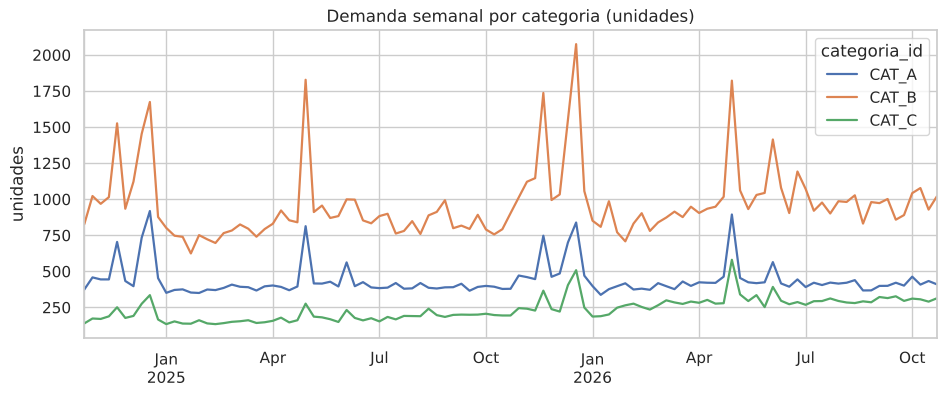

In [40]:
fig, ax = plt.subplots()
(d.groupby(["semana", "categoria_id"])["demanda_interp"].sum().unstack()
   .plot(ax=ax, linewidth=1.6))
ax.set_title("Demanda semanal por categoria (unidades)")
ax.set_xlabel(""); ax.set_ylabel("unidades")
plt.show()

## 2.2 Sazonalidade: as datas comemorativas mandam

Para isolar os picos, divido a demanda total de cada semana pela **mediana das 9 semanas ao redor**. Um índice de 2,0 significa o dobro do "normal" daquela época.

semana
2025-05-05    1.99
2025-12-22    1.97
2026-05-04    1.92
2024-12-23    1.90
2025-11-24    1.57
2024-11-25    1.50
2025-12-15    1.50
2024-12-16    1.49
2026-06-08    1.33
2025-06-09    1.22
2026-06-29    1.12
2025-09-01    1.09
Name: indice, dtype: float64


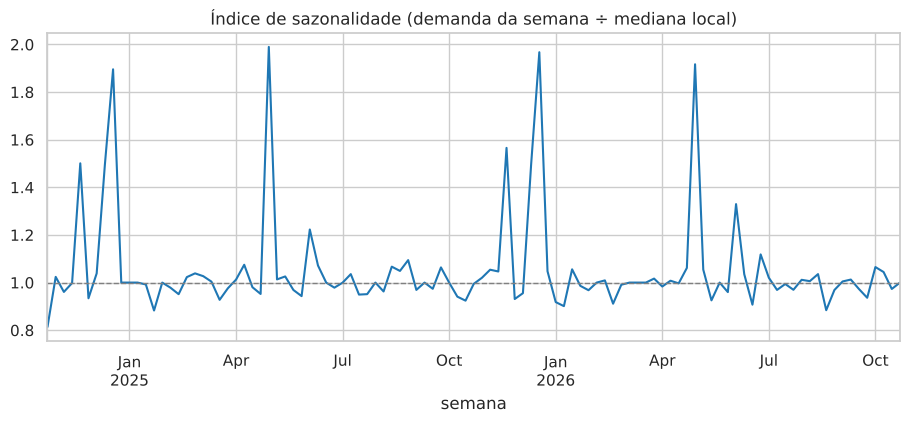

In [41]:
tot = d.groupby("semana")["demanda_interp"].sum()
indice = (tot / tot.rolling(9, center=True, min_periods=3).median()).rename("indice")
print(indice.sort_values(ascending=False).head(12).round(2))

fig, ax = plt.subplots()
indice.plot(ax=ax, color="tab:blue")
ax.axhline(1, color="grey", ls="--", lw=1)
ax.set_title("Índice de sazonalidade (demanda da semana ÷ mediana local)")
plt.show()

Os picos coincidem com o calendário de presentes do varejo de beleza:
- **Dia das Mães** (semana do 2º domingo de maio): ~2×, o maior pico do ano
- **Natal** (duas semanas antes do dia 25): até ~2×
- **Black Friday** (semana da última sexta de novembro): ~1,5×
- **Dia dos Namorados** (semana de 12/jun): ~1,2–1,3×

Isso vira **variáveis de calendário** no modelo. Sem elas, o modelo confundiria "efeito Natal" com "efeito promoção", já que as promoções também se concentram nessas datas.

In [42]:
def semana_do_evento(datas, evento):
    """Retorna a segunda-feira da semana que contém o evento, para cada ano."""
    anos = sorted(set(datas.dt.year))
    out = []
    for a in anos:
        if evento == "maes":        # 2º domingo de maio
            dom = pd.date_range(f"{a}-05-01", f"{a}-05-31", freq="W-SUN")[1]
        elif evento == "namorados":
            dom = pd.Timestamp(f"{a}-06-12")
        elif evento == "pais":      # 2º domingo de agosto
            dom = pd.date_range(f"{a}-08-01", f"{a}-08-31", freq="W-SUN")[1]
        elif evento == "black_friday":
            dom = pd.date_range(f"{a}-11-01", f"{a}-11-30", freq="W-FRI")[-1]
        elif evento == "natal":
            dom = pd.Timestamp(f"{a}-12-24")
        out.append(dom - pd.Timedelta(days=dom.dayofweek))
    return out

def features_calendario(base):
    base = base.copy()
    for ev in ["maes", "namorados", "pais", "black_friday", "natal"]:
        semanas = semana_do_evento(base["semana"], ev)
        base[f"ev_{ev}"] = base["semana"].isin(semanas).astype(int)
        # semana anterior ao evento também concentra compras de presente
        base[f"ev_{ev}_pre"] = base["semana"].isin([s - pd.Timedelta(weeks=1) for s in semanas]).astype(int)
    base["mes"] = base["semana"].dt.month
    base["semana_ano"] = base["semana"].dt.isocalendar().week.astype(int)
    return base

d = features_calendario(d)
ev_cols = [c for c in d.columns if c.startswith("ev_")]
pd.DataFrame({c: [indice[d.loc[d[c] == 1, "semana"].unique()].mean().round(2)] for c in ev_cols}, index=["índice médio"]).T

,índice médio
ev_maes,1.95
ev_maes_pre,1.01
ev_namorados,1.28
ev_namorados_pre,0.95
ev_pais,1.01
ev_pais_pre,0.96
ev_black_friday,1.53
ev_black_friday_pre,1.02
ev_natal,1.93
ev_natal_pre,1.50


### 2.2.1 Além dos picos: o 4º trimestre e o "pré-Black Friday"

Os picos de uma semana não contam a história toda. Divido a demanda de cada semana pela **semana mediana do período completo** (out/24–out/26) para enxergar o formato do Q4. A mediana praticamente ignora os picos, que são poucas semanas; usar só fev–set (um período sem datas de presente) mudaria a base em apenas ~2%, então fico com a opção mais simples, que não exige escolher janela.

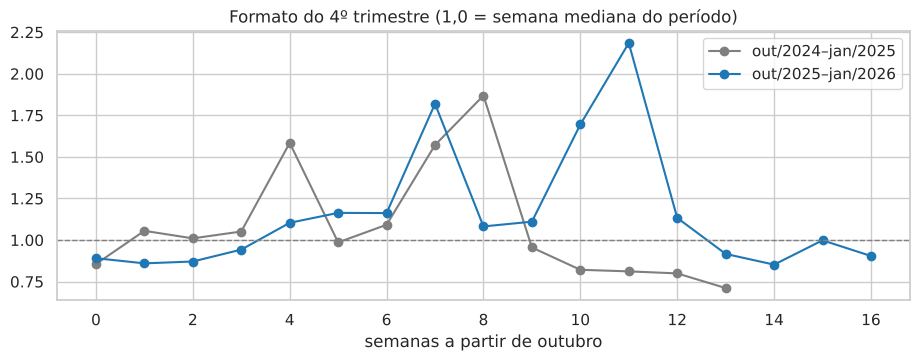

In [43]:
ref_neutra = tot.median()
idx_q4 = (tot / ref_neutra).rename("índice vs semana mediana")
fig, ax = plt.subplots(figsize=(11, 3.5))
for ano, cor in [(2024, "tab:grey"), (2025, "tab:blue")]:
    s_ = idx_q4[(idx_q4.index >= f"{ano}-10-01") & (idx_q4.index <= f"{ano + 1}-01-31")]
    ax.plot(range(len(s_)), s_.values, marker="o", color=cor, label=f"out/{ano}–jan/{ano + 1}")
ax.axhline(1, color="grey", ls="--", lw=1)
ax.set_xlabel("semanas a partir de outubro"); ax.set_title("Formato do 4º trimestre (1,0 = semana mediana do período)")
ax.legend(); plt.show()

In [44]:
cat_sem = d.groupby(["categoria_id", "semana"])["demanda_interp"].sum().unstack(0)
neutro = cat_sem.median()
semanas_ev = d.loc[d[ev_cols].any(axis=1), "semana"].unique()
q4_sem_ev = cat_sem[(cat_sem.index.quarter == 4) & ~cat_sem.index.isin(semanas_ev)]
pd.DataFrame({
    "outubro": cat_sem[cat_sem.index.month == 10].median() / neutro,
    "Q4 fora das datas comemorativas": q4_sem_ev.median() / neutro,
    "janeiro": cat_sem[cat_sem.index.month == 1].median() / neutro,
}).round(2)

,outubro,Q4 fora das datas comemorativas,janeiro
categoria_id,,,
CAT_A,0.99,1.07,0.92
CAT_B,1.00,1.10,0.87
CAT_C,0.89,0.89,0.73


In [45]:
mensal = d.groupby(d["semana"].dt.month).agg(pct_semanas_promo=("em_promo", "mean"), desconto_medio=("desconto_pct", "mean"),
                                             pct_semanas_ruptura=("teve_ruptura", "mean")).round(2)
mensal.T

semana,1,2,3,4,5,6,7,8,9,10,11,12
pct_semanas_promo,0.20,0.21,0.20,0.19,0.28,0.31,0.23,0.24,0.20,0.24,0.35,0.37
desconto_medio,8.18,7.72,8.29,7.70,9.26,10.36,8.99,8.38,8.14,9.15,11.53,11.49
pct_semanas_ruptura,0.11,0.15,0.09,0.11,0.18,0.12,0.13,0.11,0.11,0.10,0.22,0.24


**O que o Q4 mostra:**
- **Outubro é um vale:** nas semanas de outubro disponíveis (a base tem só uma de 2024), a demanda fica ~12% abaixo da semana mediana (em out/2024 e out/2025; em out/2026 o patamar inteiro está mais alto, ver abaixo). É consistente com o consumidor **segurando a compra** à espera da Black Friday.
- **Novembro "aquece" antes da BF** (até +16% nas semanas anteriores), a BF dá ~1,6–1,8× e **dezembro fica num platô** (até +10%) entre a BF e o Natal.
- **Janeiro é a ressaca:** ~8–21% abaixo da semana mediana (média do mês). Quem olha só as últimas semanas em janeiro vai superestimar.
- **A CAT_C é contrassazonal no Q4:** fora das datas comemorativas, ela fica ~11% *abaixo* da semana mediana, enquanto A e B ficam ~7–10% acima. O Q4 não é igual para todo o portfólio.
- **Promoção e ruptura se concentram no fim do ano:** em nov–dez, ~35% das semanas têm promoção (contra ~20% no resto do ano) e a ruptura chega a ~22–24%. Sazonalidade e promoção estão **confundidas**, e é por isso que os modelos de elasticidade usam efeito fixo de semana.

**Outubro de 2026 parece mais alto que o de 2025 (+25% no total). Por quê?** Comparando só os SKUs que existiam nos dois anos, a alta cai para ~+11%, e essas semanas tiveram mais promoção (29% contra 21%). O resto vem dos **lançamentos**. O crescimento orgânico, com os mesmos SKUs em fev–set, é de só ~+2%. **Não é tendência, é mix e promoção**, e por isso o modelo não precisa de um termo de tendência.

In [46]:
mesmos = d[~d["sku_id"].isin(["SKU_02", "SKU_07", "SKU_13", "SKU_19"])].groupby("semana")["demanda_interp"].sum()
total = d.groupby("semana")["demanda_interp"].sum()
pd.DataFrame({
    "total (com lançamentos)": [total["2025-10-06":"2025-10-27"].mean(), total["2026-10-05":"2026-10-26"].mean()],
    "mesmos SKUs": [mesmos["2025-10-06":"2025-10-27"].mean(), mesmos["2026-10-05":"2026-10-26"].mean()],
    "% semanas com promo": [d[d["semana"].between("2025-10-06", "2025-10-27")]["em_promo"].mean(),
                            d[d["semana"].between("2026-10-05", "2026-10-26")]["em_promo"].mean()],
}, index=["out/2025", "out/2026"]).round(2)

,total (com lançamentos),mesmos SKUs,% semanas com promo
out/2025,1395.38,1340.12,0.21
out/2026,1750.12,1492.38,0.29


## 2.3 Ruptura: quanto deixamos na mesa?

In [47]:
d["receita_perdida"] = d["qt_ruptura"] * d["preco_modelo"]
rup = (d.groupby(["categoria_id", "canal"])
         .agg(receita=("receita", "sum"), receita_perdida=("receita_perdida", "sum"),
              semanas_c_ruptura=("teve_ruptura", "mean")))
rup["perda_%_da_receita"] = (100 * rup["receita_perdida"] / rup["receita"]).round(1)
rup.round(2)

receita  receita_perdida  semanas_c_ruptura  perda_%_da_receita
categoria_id canal                                                                           
CAT_A        Loja          1306971.40         36335.22               0.13                 2.8
             Venda Direta  1264751.07         33058.17               0.14                 2.6
CAT_B        Loja          5376978.91        160794.75               0.14                 3.0
             Venda Direta  4747268.74        174908.67               0.15                 3.7
CAT_C        Loja           701993.55         25241.27               0.15                 3.6
             Venda Direta   984102.99         24753.15               0.13                 2.5

In [48]:
print("Probabilidade de ruptura na semana:")
print(d.groupby("em_promo")["teve_ruptura"].mean().rename({False: "sem promoção", True: "com promoção"}).round(3))
print("\nProbabilidade de ruptura em semanas de evento:")
print(d.groupby(d[["ev_maes", "ev_natal", "ev_black_friday"]].any(axis=1))["teve_ruptura"].mean()
        .rename({False: "semana comum", True: "Mães/Natal/BF"}).round(3))

Probabilidade de ruptura na semana:
em_promo
sem promoção    0.122
com promoção    0.187
Name: teve_ruptura, dtype: float64

Probabilidade de ruptura em semanas de evento:
semana comum     0.132
Mães/Natal/BF    0.240
Name: teve_ruptura, dtype: float64


In [49]:
top_rup = (d.groupby("serie")[["receita_perdida", "receita"]].sum()
             .assign(perda_pct=lambda x: 100 * x["receita_perdida"] / x["receita"])
             .sort_values("receita_perdida", ascending=False).head(10))
top_rup.round(1)

,receita_perdida,receita,perda_pct
serie,,,
SKU_01 | Venda Direta,134763.8,3428475.4,3.9
SKU_01 | Loja,103026.1,3739510.7,2.8
SKU_10 | Loja,16044.1,486359.7,3.3
SKU_03 | Loja,15301.8,394410.9,3.9
SKU_09 | Loja,14040.6,281279.1,5.0
SKU_17 | Loja,12092.0,343604.3,3.5
SKU_10 | Venda Direta,11797.1,253915.5,4.6
SKU_16 | Venda Direta,11133.4,308464.6,3.6
SKU_09 | Venda Direta,10389.2,286455.4,3.6


**Insight de execução:** a promoção **aumenta a chance de ruptura** (de ~12% para ~19% das semanas), e as datas de pico também (~24%). Parte do investimento promocional vira demanda gerada e não atendida. Isso reforça o valor do próprio modelo de demanda, porque prever o pico promocional permite abastecer antes.

## 2.3.1 Monitoramento de outliers

As regras da seção 1.5 pegam valores **impossíveis**. Faltam os **possíveis mas atípicos**: semanas com demanda muito acima ou abaixo do padrão da série. A regra aqui é **outlier ≠ erro**. Um pico na Black Friday é o sinal que queremos modelar, não ruído. Por isso, o monitoramento tem três etapas:

1. **Detectar com um método robusto:** para cada série, calculo o resíduo `log(demanda) − mediana móvel de 9 semanas` e o padronizo pelo **MAD** (desvio absoluto mediano). Média e desvio-padrão seriam "puxados" pelos próprios outliers; mediana e MAD não. Limite: |z| > 3,5 (regra de Iglewicz-Hoaglin).
2. **Explicar:** cada outlier é cruzado com o contexto (data comemorativa, promoção própria, ruptura, irmão em promoção).
3. **Decidir:** os explicados ficam (são sinal). Os sem explicação ficam com *flag*, e testo se mudam as conclusões (sensibilidade).

In [50]:
def monitorar_outliers(base, limite=3.5, janela=9):
    """Detecção robusta de outliers de demanda por série + classificação pelo contexto.
    Reutilizável em produção: rodar a cada carga semanal e alertar só os 'sem explicação'."""
    b = base.sort_values(CHAVE).copy()
    b["_ld"] = np.log1p(b["demanda"])
    grp = b.groupby(["sku_id", "canal"])["_ld"]
    b["residuo"] = b["_ld"] - grp.transform(lambda s: s.rolling(janela, center=True, min_periods=4).median())
    mad = b.groupby(["sku_id", "canal"])["residuo"].transform(lambda r: 1.4826 * (r - r.median()).abs().median())
    b["z_robusto"] = b["residuo"] / mad
    b["outlier"] = b["z_robusto"].abs() > limite
    # contexto: irmão de subcategoria em promoção no mesmo canal e semana
    k = ["subcategoria_id", "canal", "semana"]
    b["_irmao"] = (b.groupby(k)["em_promo"].transform("sum") - b["em_promo"]) > 0
    b["explicação"] = np.select(
        [b[ev_cols].any(axis=1), b["em_promo"], b["teve_ruptura"], (b["z_robusto"] < 0) & b["_irmao"]],
        ["data comemorativa", "promoção própria", "ruptura", "irmão em promoção"], default="sem explicação")
    return b.drop(columns=["_ld", "_irmao"])

mon = monitorar_outliers(d)
outl = mon[mon["outlier"]]
print(f"Outliers: {len(outl)} ({len(outl) / mon['demanda'].notna().sum():.1%} das semanas) — "
      f"{(outl.z_robusto > 0).sum()} acima e {(outl.z_robusto < 0).sum()} abaixo do padrão")
pd.crosstab(outl["explicação"], np.where(outl["z_robusto"] > 0, "acima", "abaixo"), margins=True)

Outliers: 128 (3.5% das semanas) — 107 acima e 21 abaixo do padrão


col_0,abaixo,acima,All
explicação,,,
data comemorativa,0,102,102
irmão em promoção,14,0,14
promoção própria,2,3,5
ruptura,2,2,4
sem explicação,3,0,3
All,21,107,128


In [51]:
sem_exp = outl[outl["explicação"] == "sem explicação"]
sem_exp[["sku_id", "canal", "semana", "demanda", "z_robusto", "desconto_pct", "qt_ruptura"]].round(2)

,sku_id,canal,semana,demanda,z_robusto,desconto_pct,qt_ruptura
316,SKU_03,Loja,2025-10-27,17.0,-3.68,4.68,0.0
418,SKU_03,Venda Direta,2025-10-06,9.0,-3.58,2.01,0.0
2927,SKU_16,Venda Direta,2026-01-05,13.0,-4.71,5.61,0.0


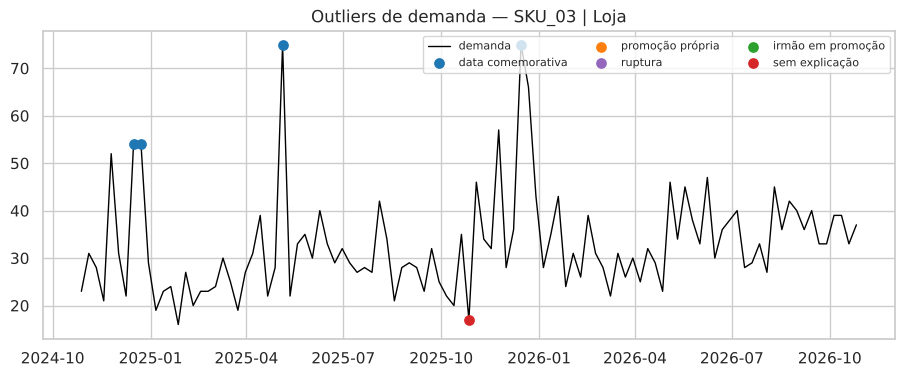

In [52]:
# visual: uma série com outliers marcados por tipo
serie_ex = sem_exp["serie"].value_counts().index[0] if len(sem_exp) else "SKU_01 | Loja"
s_ = mon[mon["serie"] == serie_ex]
fig, ax = plt.subplots()
ax.plot(s_["semana"], s_["demanda"], color="black", lw=1, label="demanda")
for tipo, cor in [("data comemorativa", "tab:blue"), ("promoção própria", "tab:orange"), ("ruptura", "tab:purple"),
                  ("irmão em promoção", "tab:green"), ("sem explicação", "tab:red")]:
    m_ = s_["outlier"] & (s_["explicação"] == tipo)
    ax.scatter(s_.loc[m_, "semana"], s_.loc[m_, "demanda"], color=cor, s=45, zorder=3, label=tipo)
ax.set_title(f"Outliers de demanda — {serie_ex}"); ax.legend(fontsize=8, ncol=3)
plt.show()

In [53]:
# outras dimensões: preço fora da faixa da série e margem destoante
preco_fora = (d["preco_modelo"] / d["preco_tabela"] > 1.10) | (d["preco_modelo"] / d["preco_tabela"] < 0.40)
desc_sem_flag = (d["desconto_pct"] > 15) & ~d["em_promo"]
margem_fora = (d["margem_pct"] - d.groupby("serie")["margem_pct"].transform("median")).abs() > 5
pd.Series({"preço > 110% ou < 40% da tabela": int(preco_fora.sum()),
           "desconto > 15% sem tipo de desconto marcado": int(desc_sem_flag.sum()),
           "margem a mais de 5 p.p. da mediana da série": int(margem_fora.sum())})

preço > 110% ou < 40% da tabela                0
desconto > 15% sem tipo de desconto marcado    0
margem a mais de 5 p.p. da mediana da série    0
dtype: int64

In [54]:
# sensibilidade: as elasticidades mudam se eu tirar os outliers sem explicação?
d["flag_outlier_sem_explicacao"] = d.set_index(CHAVE).index.isin(sem_exp.set_index(CHAVE).index)
F_SENS = "log_demanda ~ log_preco_rel + flag_desconto_direto + flag_combo + flag_pague_e_leve + C(serie) + C(semana)"   # mesma da seção 2.4
sens = []
for (cat, can), grp in d.groupby(["categoria_id", "canal"]):
    b1 = grp.dropna(subset=["log_demanda"])
    b2 = b1[~b1["flag_outlier_sem_explicacao"]]
    sens.append({"categoria": cat, "canal": can,
                 "elasticidade (todos)": smf.ols(F_SENS, b1).fit().params["log_preco_rel"],
                 "elasticidade (sem outliers s/ explicação)": smf.ols(F_SENS, b2).fit().params["log_preco_rel"]})
pd.DataFrame(sens).round(3)

,categoria,canal,elasticidade (todos),elasticidade (sem outliers s/ explicação)
0,CAT_A,Loja,-1.677,-1.677
1,CAT_A,Venda Direta,-1.354,-1.354
2,CAT_B,Loja,-0.229,-0.248
3,CAT_B,Venda Direta,-0.073,-0.053
4,CAT_C,Loja,-0.091,-0.091
5,CAT_C,Venda Direta,-0.058,-0.052


**Leitura:**
- **~3% das semanas são outliers**, e a grande maioria é **pico explicado por data comemorativa**. É o sinal que o modelo precisa capturar, e por isso os eventos viraram features.
- **Das 21 quedas atípicas, 14 acontecem com um irmão em promoção.** É a **canibalização da CAT_A** aparecendo como outlier, sobretudo no SKU_08 na Loja quando o SKU_04 está em promoção. Sem essa explicação, eu as teria tratado como erro de dados. É um bom exemplo de por que outlier precisa de contexto antes de virar correção.
- **Só 3 semanas ficam sem explicação** (SKU_03 em out/25 e SKU_16 em jan/26): quedas moderadas, sem promoção, ruptura ou evento. Podem ser falhas parciais de registro ou eventos locais que a base não registra (falta de exposição em loja, por exemplo). Eu perguntaria ao negócio.
- **Preço e margem não têm outliers** depois da limpeza da seção 1.5.
- **Decisão:** manter todos, com a flag `flag_outlier_sem_explicacao`. O teste de sensibilidade mostra que **as elasticidades praticamente não mudam** sem eles, então não vale a pena "corrigir" dados sem uma razão de negócio.
- **Em produção**, a função `monitorar_outliers` roda a cada carga semanal e **só alerta os "sem explicação"**, para não gerar ruído com picos de BF. Ela também é um termômetro de qualidade de dados: se a contagem semanal de casos sem explicação subir, algo mudou na origem.

## 2.4 Elasticidade-preço: modelo log-log com efeitos fixos

**Ideia:** num modelo `log(demanda) = β · log(preço relativo) + ...`, o coeficiente β é a **elasticidade**: um preço 1% menor gera |β|% mais volume.

**Por que efeitos fixos?**
- **Efeito fixo de série (SKU×canal):** compara cada produto com ele mesmo. Sem isso, o modelo concluiria que "produto caro vende pouco", o que mistura preço com tipo de produto.
- **Efeito fixo de semana:** absorve a sazonalidade e choques comuns. Promoções são concentradas em datas de pico, e sem esse controle o efeito Natal seria atribuído ao desconto (**viés de endogeneidade**).

Incluo também as dummies de **tipo de desconto** (desconto direto, combo e pague e leve, cada uma 0 ou 1). Assim separo o efeito **via preço** do efeito **extra do tipo de desconto** (visibilidade, percepção de vantagem).

**É uma regressão em painel:** as mesmas séries (SKU × canal) observadas semana a semana, de 28/10/2024 a 26/10/2026 (105 semanas). Rodo 6 regressões (categoria × canal), cada uma com 6–7 séries, 3.659 observações no total. O painel é **desbalanceado**: os lançamentos entram a partir da primeira semana de venda e as 71 semanas de zero suspeito ficam fora.

**Erros-padrão agrupados por série:** semanas da mesma série são correlacionadas, e o erro-padrão comum seria otimista demais.

In [55]:
FORMULA = "log_demanda ~ log_preco_rel + flag_desconto_direto + flag_combo + flag_pague_e_leve + C(serie) + C(semana)"

def ajustar(base):
    b = base.dropna(subset=["log_demanda"]).copy()
    grupos = b["serie"].astype("category").cat.codes
    return smf.ols(FORMULA, data=b).fit(cov_type="cluster", cov_kwds={"groups": grupos})

termos = {"log_preco_rel": "elasticidade",
          "flag_desconto_direto[T.True]": "desconto direto (extra)",
          "flag_combo[T.True]": "combo (extra)",
          "flag_pague_e_leve[T.True]": "pague e leve (extra)"}

linhas, modelos_el = [], {}
for (cat, can), grp in d.groupby(["categoria_id", "canal"]):
    m = ajustar(grp)
    modelos_el[(cat, can)] = m
    linha = {"categoria": cat, "canal": can, "n": int(m.nobs)}
    for t, nome in termos.items():
        linha[nome] = m.params[t]
        linha[nome + " p"] = m.pvalues[t]
    linhas.append(linha)
elast = pd.DataFrame(linhas)
elast.round(3)

,categoria,canal,n,elasticidade,elasticidade p,desconto direto (extra),desconto direto (extra) p,combo (extra),combo (extra) p,pague e leve (extra),pague e leve (extra) p
0,CAT_A,Loja,719,-1.677,0.000,-0.035,0.677,0.131,0.293,0.053,0.665
1,CAT_A,Venda Direta,723,-1.354,0.000,0.110,0.375,0.226,0.074,0.274,0.004
2,CAT_B,Loja,591,-0.229,0.095,-0.012,0.349,0.077,0.086,0.099,0.032
3,CAT_B,Venda Direta,589,-0.073,0.567,0.071,0.022,0.138,0.000,0.192,0.000
4,CAT_C,Loja,520,-0.091,0.503,0.031,0.343,0.130,0.014,0.162,0.000
5,CAT_C,Venda Direta,517,-0.058,0.628,0.079,0.000,0.147,0.000,0.187,0.000


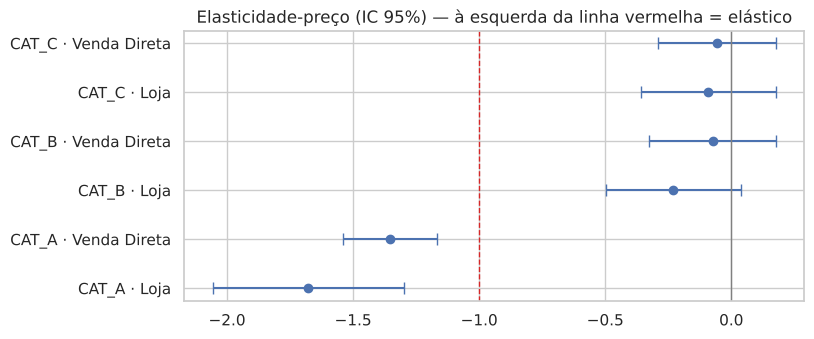

In [56]:
fig, ax = plt.subplots(figsize=(8, 3.5))
plot_el = elast.assign(grupo=elast["categoria"] + " · " + elast["canal"])
ics = [modelos_el[(r.categoria, r.canal)].conf_int().loc["log_preco_rel"] for r in elast.itertuples()]
ax.errorbar(plot_el["elasticidade"], plot_el["grupo"],
            xerr=[plot_el["elasticidade"] - [i[0] for i in ics], [i[1] for i in ics] - plot_el["elasticidade"]],
            fmt="o", capsize=4)
ax.axvline(0, color="grey", lw=1); ax.axvline(-1, color="tab:red", lw=1, ls="--")
ax.set_title("Elasticidade-preço (IC 95%) — à esquerda da linha vermelha = elástico")
plt.show()

**Como ler (tradução para negócio):**
- **CAT_A é elástica** (|β| > 1): um desconto de 10% aumenta o volume em mais de 10%, então a receita *sobe* com o desconto. É a categoria em que **preço funciona como alavanca**. *Atenção:* este modelo ainda não controla a promoção dos irmãos. Na seção 2.7, com esse controle, a magnitude cai para −1,0 a −1,3. A CAT_A segue sendo a mais sensível, mas "elástica" passa a depender do modelo (ver o rodízio de promoções na seção 2.6.2).
- **CAT_B e CAT_C são inelásticas** (β próximo de 0): o desconto quase não move volume. **Desconto ali é margem jogada fora**, a menos que o tipo de desconto tenha um efeito próprio.
- Os **tipos de desconto combo e pague-e-leve têm efeito extra positivo** além do preço, inclusive nas categorias inelásticas. O efeito extra do desconto direto é pequeno (0 a +8%), ou seja, ele age quase só pelo preço.
- A **Venda Direta reage mais aos tipos de desconto** do que a Loja. Isso faz sentido, porque a consultora "vende" a oferta ativamente.

Como converter um coeficiente log em %: efeito = `exp(β) − 1`. Por exemplo, β = 0,19 → +21% de volume.

## 2.5 ROI por tipo de desconto: volume não é tudo

**Problema detectado:** a `margem_pct` quase **não varia com o desconto** dentro de cada série (correlação ~0). Na vida real, dar 30% de desconto derruba a margem sobre o preço. É uma inconsistência que eu **levaria para o negócio** ("a margem já desconta verba de fornecedor? é margem de tabela?").

**Abordagem para não depender dela:** estimo um **custo unitário** por série a partir das semanas *sem* promoção (`custo = preço × (1 − margem)`) e recalculo o lucro bruto de cada semana como `(preço − custo) × quantidade`.

**Contrafactual (o que teria acontecido sem promoção):** uso os coeficientes do modelo da seção 2.4. Como o modelo é multiplicativo, `demanda_base = demanda ÷ exp(efeito da promoção)`. A vantagem é que o efeito de sazonalidade já está separado.

In [57]:
sem_promo = d[~d["em_promo"] & d["preco_medio"].notna()]
custo = (sem_promo["preco_medio"] * (1 - sem_promo["margem_pct"] / 100)).groupby(sem_promo["serie"]).median()
preco_regular = sem_promo.groupby("serie")["preco_medio"].median()
d["custo_unit"] = d["serie"].map(custo)
d["preco_regular"] = d["serie"].map(preco_regular)

def efeito_promo(linha):
    m = modelos_el[(linha["categoria_id"], linha["canal"])]
    e = m.params["log_preco_rel"] * (linha["log_preco_rel"] - np.log(linha["preco_regular"] / linha["preco_tabela"]))
    for f in FLAGS:
        e += m.params[f + "[T.True]"] * linha[f]
    return e

p = d[d["em_promo"] & d["demanda"].notna()].copy()
p["efeito_log"] = p.apply(efeito_promo, axis=1)
p["demanda_base"] = p["demanda"] / np.exp(p["efeito_log"])
p["lucro_promo"] = (p["preco_modelo"] - p["custo_unit"]) * p["demanda"]
p["lucro_base"] = (p["preco_regular"] - p["custo_unit"]) * p["demanda_base"]
p["mecanica"] = np.select([p["n_mecanicas"] > 1, p["flag_desconto_direto"], p["flag_combo"], p["flag_pague_e_leve"]],
                          ["múltiplas", "desconto direto", "combo", "pague e leve"], default="outra")

roi = (p.groupby(["categoria_id", "mecanica"])
         .agg(semanas=("demanda", "size"), desconto_medio=("desconto_pct", "mean"),
              demanda=("demanda", "sum"), demanda_base=("demanda_base", "sum"),
              lucro_promo=("lucro_promo", "sum"), lucro_base=("lucro_base", "sum")))
roi["uplift_volume_%"] = 100 * (roi["demanda"] / roi["demanda_base"] - 1)
roi["delta_lucro_%"] = 100 * (roi["lucro_promo"] / roi["lucro_base"] - 1)
roi[["semanas", "desconto_medio", "uplift_volume_%", "delta_lucro_%"]].round(1)

semanas  desconto_medio  uplift_volume_%  delta_lucro_%
categoria_id mecanica                                                                
CAT_A        combo                209            31.7            105.3          -34.7
             desconto direto      192            28.4             65.1          -32.8
             múltiplas              4            33.7            125.0          -34.8
             pague e leve         157            33.1            106.5          -41.3
CAT_B        combo                 75            23.0             14.6          -28.7
             desconto direto      102            21.1              6.3          -29.9
             múltiplas              5            29.1             30.9          -45.4
             pague e leve          42            29.3             21.8          -44.3
CAT_C        combo                 52            24.0             16.6          -32.0
             desconto direto       73            19.6              7.3          -29.8
             múltiplas              4            28.0             28.8          -31.0
             pague e leve          32            26.5             21.6          -32.4

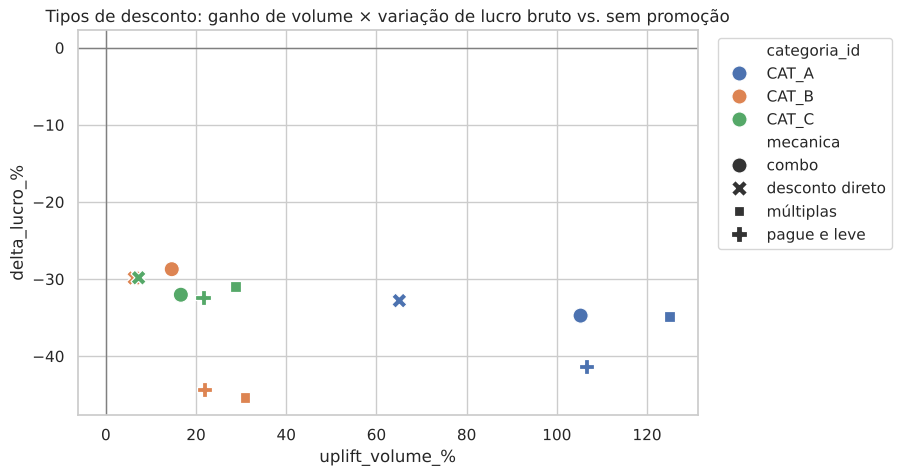

In [58]:
fig, ax = plt.subplots(figsize=(8, 5))
r = roi.reset_index()
sns.scatterplot(data=r, x="uplift_volume_%", y="delta_lucro_%", hue="categoria_id", style="mecanica", s=120, ax=ax)
ax.axhline(0, color="grey", lw=1); ax.axvline(0, color="grey", lw=1)
ax.set_title("Tipos de desconto: ganho de volume × variação de lucro bruto vs. sem promoção")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

**Leitura:** **nenhum tipo de desconto se paga em lucro bruto no curto prazo.** Todas ficam no quadrante "mais volume, menos lucro".
- Na **CAT_A** (elástica), a promoção dobra o volume (+65% a +107%), mas ainda perde ~33–41% do lucro bruto da semana.
- Na **CAT_B e CAT_C** (inelásticas), o volume sobe só 6–22% e o lucro cai ~30–45%. O **desconto direto é o pior caso**: quase não gera volume.

**Por quê? A conta do ponto de equilíbrio.** Com margem *m* e desconto *δ* (ambos sobre o preço cheio), o volume precisa crescer `δ / (m − δ)` só para o lucro empatar:

In [59]:
for m_, dlt in [(0.44, 0.10), (0.44, 0.20), (0.44, 0.28), (0.52, 0.25)]:
    print(f"margem {m_:.0%}, desconto {dlt:.0%} → precisa de +{dlt / (m_ - dlt):.0%} de volume para empatar o lucro")

margem 44%, desconto 10% → precisa de +29% de volume para empatar o lucro
margem 44%, desconto 20% → precisa de +83% de volume para empatar o lucro
margem 44%, desconto 28% → precisa de +175% de volume para empatar o lucro
margem 52%, desconto 25% → precisa de +93% de volume para empatar o lucro


Com margem de ~44% e desconto médio de ~28%, seria preciso **+175% de volume** para empatar, e nenhum tipo de desconto chega lá. Daí vêm as recomendações:
1. **Descontos mais rasos** (10–15%), sobretudo nas categorias inelásticas.
2. Reservar promoção para objetivos que o lucro semanal não captura: **aquisição/recompra, giro de estoque, defesa de share**. E medir esses objetivos.
3. Nas inelásticas, preferir **combo/pague-e-leve**, que geram 2–3× mais volume que o desconto direto com desconto parecido.

*Limitação honesta:* o contrafactual depende do modelo de elasticidade, e os custos foram estimados. Em produção, eu validaria com **testes A/B ou regiões de controle**.

## 2.6 Canibalização: a promoção de um SKU rouba venda do irmão?

**Variável construída:** `irmao_promo` é a fração dos *outros* SKUs da **mesma subcategoria e canal** que estão em promoção na semana. Se o coeficiente for negativo, a promoção do irmão **tira** demanda deste SKU. Para comparar, uso `outra_sub_promo` (promo em outras subcategorias da mesma categoria): se o efeito for só ali, seria um efeito de categoria, não de substituição direta.

In [60]:
def add_irmaos(base):
    base = base.copy()
    k = ["subcategoria_id", "canal", "semana"]
    s = base.groupby(k)["em_promo"].agg(n_sub="size", p_sub="sum").reset_index()
    base = base.merge(s, on=k, how="left")
    base["irmao_promo"] = ((base["p_sub"] - base["em_promo"]) / (base["n_sub"] - 1)).where(base["n_sub"] > 1, 0)
    kc = ["categoria_id", "canal", "semana"]
    s2 = base.groupby(kc)["em_promo"].agg(n_cat="size", p_cat="sum").reset_index()
    base = base.merge(s2, on=kc, how="left")
    base["outra_sub_promo"] = ((base["p_cat"] - base["p_sub"]) / (base["n_cat"] - base["n_sub"])).where(base["n_cat"] > base["n_sub"], 0)
    return base.drop(columns=["n_sub", "p_sub", "n_cat", "p_cat"])

d = add_irmaos(d)
F_CANIB = FORMULA + " + irmao_promo + outra_sub_promo"
lin = []
for cat, grp in d.groupby("categoria_id"):
    b = grp.dropna(subset=["log_demanda"])
    m = smf.ols(F_CANIB, b).fit(cov_type="cluster", cov_kwds={"groups": b["serie"].astype("category").cat.codes})
    for t in ["irmao_promo", "outra_sub_promo"]:
        lin.append({"categoria": cat, "variável": t, "coef": m.params[t], "efeito_%_se_todos_em_promo": 100 * (np.exp(m.params[t]) - 1), "p_valor": m.pvalues[t]})
pd.DataFrame(lin).round(3)

,categoria,variável,coef,efeito_%_se_todos_em_promo,p_valor
0,CAT_A,irmao_promo,-0.472,-37.605,0.000
1,CAT_A,outra_sub_promo,0.150,16.143,0.039
2,CAT_B,irmao_promo,0.012,1.209,0.507
3,CAT_B,outra_sub_promo,0.012,1.163,0.753
4,CAT_C,irmao_promo,-0.021,-2.108,0.283
5,CAT_C,outra_sub_promo,-0.027,-2.644,0.085


**Leitura:** a canibalização é **forte e significativa na CAT_A**: com todos os irmãos de subcategoria em promoção, o SKU perde ~38% da demanda. Nas CAT_B e CAT_C, o efeito é ~0. Na CAT_A aparece ainda um leve efeito *positivo* de promoção em outras subcategorias (~+16%, p ≈ 0,04), possivelmente tráfego ou cesta. É um indício, não uma conclusão.

Isso fecha a história da CAT_A: ela é **elástica, mas parte do volume que a promoção gera é transferido do irmão**, e não demanda nova. O uplift *líquido* da subcategoria é menor do que o uplift do SKU promovido. **Recomendação:** na CAT_A, evitar promover irmãos em semanas diferentes de forma alternada e medir o resultado no nível da subcategoria.

### 2.6.1 Lançamentos: o produto novo canibaliza os existentes?

Uso **diferenças-em-diferenças (DiD)**, comparando antes e depois do lançamento (±12 semanas):
- **Tratados:** SKUs da mesma subcategoria do lançamento.
- **Controle:** SKUs de outras subcategorias da mesma categoria.

O coeficiente `did` é a variação **adicional** da demanda dos irmãos após o lançamento, já descontando o que aconteceu com o grupo de controle no mesmo período (sazonalidade etc.).

In [61]:
primeira = d.groupby("sku_id")["semana"].min()
lancamentos = primeira[primeira > d["semana"].min()].index.tolist()
res = []
for sk in lancamentos:
    t0, sub = primeira[sk], d.loc[d["sku_id"] == sk, "subcategoria_id"].iloc[0]
    w = d[(d["categoria_id"] == sub[:5]) & (~d["sku_id"].isin(lancamentos))
          & d["semana"].between(t0 - pd.Timedelta(weeks=12), t0 + pd.Timedelta(weeks=11))].copy()
    w["did"] = ((w["subcategoria_id"] == sub) & (w["semana"] >= t0)).astype(int)
    w["ldi"] = np.log(w["demanda_interp"])
    m = smf.ols("ldi ~ did + C(serie) + C(semana)", w).fit()
    res.append({"lançamento": sk, "início": t0.date(), "subcategoria": sub,
                "irmãos": ", ".join(sorted(w.loc[w["subcategoria_id"] == sub, "sku_id"].unique())),
                "efeito_nos_irmãos_%": 100 * (np.exp(m.params["did"]) - 1), "p_valor": m.pvalues["did"],
                "demanda_média_lançamento": d.loc[d["sku_id"] == sk, "demanda_interp"].mean()})
pd.DataFrame(res).round(3)

,lançamento,início,subcategoria,irmãos,efeito_nos_irmãos_%,p_valor,demanda_média_lançamento
0,SKU_02,2026-04-27,CAT_B_SUB1,"SKU_01, SKU_03",2.746,0.543,24.556
1,SKU_07,2025-10-27,CAT_B_SUB2,SKU_06,-4.607,0.411,44.057
2,SKU_13,2026-01-26,CAT_C_SUB1,"SKU_11, SKU_15",3.101,0.513,40.688
3,SKU_19,2025-07-28,CAT_C_SUB2,"SKU_16, SKU_18",0.145,0.972,21.114


Nenhum lançamento reduziu de forma significativa a demanda dos irmãos (p > 0,4). Os lançamentos foram **incrementais**, trazendo volume novo sem tirar dos existentes. É um bom argumento a favor da estratégia de inovação do portfólio.

### 2.6.2 Como a canibalização é medida, e o que pode distorcer a medida

Uso **duas medidas**, cada uma com premissas diferentes. Quando elas concordam, a conclusão fica robusta:

| Medida | Variável explicativa | Pergunta que responde | Premissas principais |
|---|---|---|---|
| **Regressão com efeitos fixos** (2.6) | `irmao_promo`: fração dos irmãos da subcategoria em promoção na semana | "Quanto o SKU perde quando os irmãos estão em promoção?" | Todos os irmãos pesam igual; a profundidade do desconto do irmão não importa; o efeito é igual para todos os SKUs da categoria |
| **Diferenças-em-diferenças** (2.6.1) | entrada de um lançamento | "Um produto novo rouba venda dos existentes?" | Tendências paralelas entre a subcategoria tratada e o controle |
#
**Como a granularidade afeta o cálculo:**
- **Grupo de substituição = subcategoria.** É uma premissa forte: se dois SKUs de subcategorias diferentes forem substitutos, o efeito não é medido. Na CAT_A, a regressão encontrou até um leve efeito **positivo** de promoções em outras subcategorias, o que é compatível com tráfego e não com substituição. Com 2–3 SKUs por subcategoria, cada par tem pouca informação, por isso a medida usa a *fração* de irmãos em promoção em vez de pares individuais.
- **Canal:** os modelos assumem que a canibalização acontece **dentro** do canal. Se a consultora em promoção tirasse venda da loja, isso não apareceria. O teste abaixo verifica essa premissa.
- **Semana:** se o cliente **estoca** na promoção (*pantry loading*), a venda cai nas semanas **seguintes**, e a perda aparece como "efeito de dinâmica", não como canibalização. Também testo isso abaixo.
- **Profundidade do desconto:** `irmao_promo` conta *se* o irmão está em promoção, não *quanto* de desconto ele dá. Uma promoção de 10% e uma de 35% pesam igual.

In [62]:
d_ = d.sort_values(CHAVE).copy()
# 1) os irmãos fazem promoção ao mesmo tempo ou em rodízio?
cat_sku_eda = d.drop_duplicates("sku_id").set_index("sku_id")["categoria_id"]
lp = d_.pivot_table(index=["canal", "semana"], columns="sku_id", values="log_preco_rel")
pr = d_.pivot_table(index=["canal", "semana"], columns="sku_id", values="em_promo", aggfunc="max").astype(float)
pares = [("SKU_04", "SKU_08"), ("SKU_05", "SKU_12"), ("SKU_14", "SKU_17"), ("SKU_05", "SKU_20"), ("SKU_01", "SKU_03"), ("SKU_09", "SKU_10")]
rodizio = pd.DataFrame([{"par": f"{a} × {b}", "categoria": cat_sku_eda[a],
                         "correlação do preço": lp[a].corr(lp[b]),
                         "% semanas ambos em promo": (pr[a] * pr[b]).mean(),
                         "esperado se independentes": pr[a].mean() * pr[b].mean()} for a, b in pares])
rodizio.round(3)

,par,categoria,correlação do preço,% semanas ambos em promo,esperado se independentes
0,SKU_04 × SKU_08,CAT_A,-0.312,0.095,0.139
1,SKU_05 × SKU_12,CAT_A,-0.549,0.119,0.252
2,SKU_14 × SKU_17,CAT_A,-0.288,0.095,0.147
3,SKU_05 × SKU_20,CAT_A,0.014,0.100,0.084
4,SKU_01 × SKU_03,CAT_B,0.042,0.043,0.032
5,SKU_09 × SKU_10,CAT_B,0.192,0.062,0.033


In [63]:
# 2) estocagem: a demanda cai na semana seguinte à promoção?
nivel_sp = d_.groupby(["sku_id", "canal"])["demanda"].transform(lambda s: s.where(~d_.loc[s.index, "em_promo"]).rolling(13, center=True, min_periods=4).median())
d_["razao"] = d_["demanda"] / nivel_sp
d_["promo_semana_anterior"] = d_.groupby(["sku_id", "canal"])["em_promo"].shift(1)
sem_p = d_[~d_["em_promo"]]
# 3) canibalização entre canais: a promoção no OUTRO canal tira venda deste?
outro_c = d_[["sku_id", "canal", "semana", "em_promo"]].assign(canal=lambda x: np.where(x["canal"] == "Loja", "Venda Direta", "Loja")).rename(columns={"em_promo": "promo_outro_canal"})
d_ = d_.merge(outro_c, on=["sku_id", "canal", "semana"])
sem_p2 = d_[~d_["em_promo"]]
pd.Series({
    "pós-promoção: demanda ÷ nível normal": sem_p.loc[sem_p["promo_semana_anterior"] == True, "razao"].median(),
    "outras semanas sem promo: demanda ÷ nível normal": sem_p.loc[sem_p["promo_semana_anterior"] == False, "razao"].median(),
    "sem promo própria, OUTRO canal em promo: demanda ÷ nível": sem_p2.loc[sem_p2["promo_outro_canal"] == True, "razao"].median(),
    "sem promo própria, outro canal sem promo: demanda ÷ nível": sem_p2.loc[sem_p2["promo_outro_canal"] == False, "razao"].median(),
    "% das promoções sincronizadas entre canais": (d_["em_promo"] & d_["promo_outro_canal"]).sum() / d_["em_promo"].sum(),
}).round(3)

pós-promoção: demanda ÷ nível normal                         1.000
outras semanas sem promo: demanda ÷ nível normal             1.000
sem promo própria, OUTRO canal em promo: demanda ÷ nível     1.024
sem promo própria, outro canal sem promo: demanda ÷ nível    1.000
% das promoções sincronizadas entre canais                   0.529
dtype: float64

**O que as checagens mostram:**
1. **Na CAT_A, os irmãos fazem promoção em rodízio:** o preço de um sobe quando o do outro cai (correlação de −0,3 a −0,55), e as semanas com os dois em promoção são **menos frequentes** do que o acaso daria. Isso tem uma consequência técnica importante: o efeito do **preço próprio** e o do **preço do irmão** ficam **parcialmente colineares**. Quando o SKU está em promoção, o irmão geralmente não está, e vice-versa. O modelo identifica bem o **efeito total do rodízio**, mas a **divisão** entre "elasticidade própria" e "canibalização" depende da especificação. É por isso que a elasticidade da CAT_A cai de −1,7 (sem termo de irmão) para −1,0/−1,3 quando a promoção do irmão entra no modelo (seção 2.7): parte do que parecia resposta ao próprio preço era o irmão **saindo** de promoção. *Essa é a ressalva mais importante sobre os números de elasticidade.*
2. **Não há estocagem visível:** a semana seguinte a uma promoção vende o normal (1,0×). A granularidade semanal não esconde um "vale pós-promoção", então não é preciso modelar dinâmica de estoque do consumidor.
3. **Não há canibalização entre canais:** quando o outro canal está em promoção, a demanda deste fica no nível normal (~1,0×, até +2%). A premissa "substituição só dentro do canal" se sustenta. Como ~53% das promoções são sincronizadas entre canais, parte da comparação Loja × VD vem de promoções simultâneas, o que ajuda a compará-los em condições iguais.

## 2.7 A elasticidade e a canibalização são iguais nos dois canais?

Loja e Venda Direta têm compradores e dinâmicas diferentes. Na VD, a consultora "vende" a oferta, e o cliente pode ser mais sensível a preço, ou menos, porque compra pela relação com a consultora. Se as elasticidades forem diferentes, preço e promoção deveriam ser **planejados por canal**.

Faço a análise em dois passos: (1) estimar e testar a diferença com o modelo de efeitos fixos; (2) perguntar **se há dados suficientes** para detectar uma diferença.

### 2.7.1 Efeitos fixos por categoria × canal, agora controlando a canibalização

In [64]:
from scipy.stats import norm as _norm
F_CANAL = ("log_demanda ~ log_preco_rel + irmao_promo + flag_desconto_direto + flag_combo + flag_pague_e_leve"
           " + C(serie) + C(semana)")
linhas = []
for (cat, can), grp in d.groupby(["categoria_id", "canal"]):
    b = grp.dropna(subset=["log_demanda"])
    m_hc = smf.ols(F_CANAL, b).fit(cov_type="HC1")
    m_cl = smf.ols(F_CANAL, b).fit(cov_type="cluster", cov_kwds={"groups": b["serie"].astype("category").cat.codes})
    for t in ["log_preco_rel", "irmao_promo"]:
        # com só 6–7 séries por grupo, o erro-padrão agrupado é pouco confiável: uso o MAIOR dos dois (conservador)
        linhas.append({"categoria": cat, "canal": can, "termo": t, "coef": m_hc.params[t],
                       "ep": max(m_hc.bse[t], m_cl.bse[t])})
ef_canal = pd.DataFrame(linhas)
tab = ef_canal.pivot_table(index=["termo", "categoria"], columns="canal", values=["coef", "ep"])
tab["diferença (VD − Loja)"] = tab[("coef", "Venda Direta")] - tab[("coef", "Loja")]
tab["ep da diferença"] = np.sqrt(tab[("ep", "Venda Direta")] ** 2 + tab[("ep", "Loja")] ** 2)
tab["p-valor"] = 2 * (1 - _norm.cdf((tab["diferença (VD − Loja)"] / tab["ep da diferença"]).abs()))
tab["MDE 80%"] = 2.8 * tab["ep da diferença"]   # menor diferença detectável com 80% de poder e 5% de significância
tab.round(3)

coef                  ep              diferença (VD − Loja) ep da diferença p-valor MDE 80%
canal                     Loja Venda Direta   Loja Venda Direta                                                      
termo         categoria                                                                                              
irmao_promo   CAT_A     -0.505       -0.500  0.041        0.039                 0.005           0.057   0.932   0.160
              CAT_B      0.019       -0.002  0.021        0.031                -0.021           0.037   0.568   0.104
              CAT_C     -0.020        0.016  0.028        0.029                 0.036           0.041   0.374   0.114
log_preco_rel CAT_A     -1.315       -1.005  0.219        0.172                 0.310           0.279   0.266   0.780
              CAT_B     -0.237       -0.074  0.135        0.143                 0.164           0.197   0.406   0.552
              CAT_C     -0.090       -0.057  0.136        0.116                 0.033           0.179   0.854   0.501

**Leitura:**
- **Nenhuma diferença entre canais é estatisticamente significativa**, nem na elasticidade-preço nem na canibalização.
- Na CAT_A, a elasticidade estimada é −1,3 na Loja e −1,0 na VD. A diferença de 0,3 parece relevante para o negócio, mas o **MDE** mostra que, com estes dados, só se detectaria uma diferença acima de **~0,8**. Ou seja, *ausência de evidência não é evidência de ausência*.
- A canibalização na CAT_A é praticamente **idêntica nos dois canais** (~−0,50), e ali o MDE é pequeno (~0,16). **Esta é uma conclusão firme: canibalização igual nos dois canais.**
- **Efeito colateral didático:** ao incluir `irmao_promo`, a elasticidade da CAT_A cai de ~−1,7/−1,4 (seção 2.4) para ~−1,3/−1,0. Sem controlar a promoção dos irmãos, parte da queda de venda que ela causa era atribuída ao preço do próprio SKU (**viés de variável omitida**). O número da 2.7 é o mais correto.

### 2.7.2 Dá para fazer isso bem com ~3.700 linhas?

O número de linhas engana. O que identifica a elasticidade é a **variação de preço dentro de cada série**, e ela é pequena:

In [65]:
info = d.groupby("serie").agg(categoria=("categoria_id", "first"), semanas=("semana", "size"),
                              semanas_promo=("em_promo", "sum"), dp_log_preco=("log_preco_rel", "std"))
info.groupby("categoria")[["semanas", "semanas_promo", "dp_log_preco"]].median().round(3)

,semanas,semanas_promo,dp_log_preco
categoria,,,
CAT_A,105.0,41.0,0.196
CAT_B,105.0,17.0,0.114
CAT_C,105.0,13.5,0.096


- O preço de tabela é fixo, então **toda a variação de preço vem das promoções**: cerca de 15–40 semanas promocionais por série.
- Por categoria e canal, são só **6–7 séries**. Para comparar canais, a unidade de informação efetiva é "SKU × episódio de promoção", não a linha.
- Variação de preço baixa (desvio-padrão de ~0,1 em log nas categorias B e C) significa estimativas imprecisas de elasticidade, e é justamente onde a elasticidade é ~0.

**Veredito:** os dados bastam para elasticidade **por categoria** e para **canibalização** (efeito grande, estimado com precisão), mas **não para afirmar diferenças de elasticidade entre canais**. *"Os dados mostram que a canibalização na CAT_A é forte e igual nos dois canais. Não permitem afirmar que a elasticidade difere entre canais. Antes de diferenciar preço por canal, eu faria um teste A/B."*

> *Próximo passo possível:* um modelo bayesiano hierárquico (ex.: pacote `pypricing`) estimaria elasticidades por SKU emprestando força do grupo. Testei na versão anterior: a ordem das categorias se mantém, e a conclusão sobre canais é a mesma.

## 2.8 Resumo de insights para o negócio

1. **Calendário manda:** Dia das Mães e Natal dobram a demanda, e a Black Friday a aumenta em ~50%. Planejamento de estoque e de promoção deve partir daqui.
2. **Ruptura custa ~2,5–3,7% da receita e piora na promoção e nos picos:** a chance de ruptura vai de ~12% para ~19% com promoção e para ~24% em Mães/Natal/BF. O SKU_01 (o maior) concentra a maior perda absoluta.
3. **Preço só mexe volume na CAT_A** (elasticidade entre −1,0 e −1,7, dependendo de como se controla a canibalização; ver 2.6.2 e 2.7). Em B e C, a elasticidade é ~0.
4. **Combo e pague-e-leve funcionam além do preço**, especialmente na Venda Direta, e são os tipos de desconto preferíveis nas categorias inelásticas.
5. **Mas nenhuma promoção se paga em lucro bruto semanal:** com margem de ~44% e desconto de ~28%, seria preciso +175% de volume. A recomendação é ter descontos mais rasos e medir objetivos de longo prazo.
6. **Canibalização relevante na CAT_A** entre SKUs da mesma subcategoria: medir promoções pelo resultado da subcategoria, não do SKU.
7. **Lançamentos foram incrementais**, sem canibalização detectável.
8. **Qualidade de dados:** a margem não reage ao desconto, o que precisa ser validado com Finanças antes de decisões de preço baseadas em margem.
9. **O Q4 tem formato próprio:** outubro é um vale (espera pela BF), novembro aquece, dezembro fica num platô e janeiro é ressaca. A CAT_C é contrassazonal no Q4.
10. **Canais:** a canibalização é igual em Loja e VD. Para elasticidade, os dados não permitem afirmar diferença entre canais (seção 2.7). A recomendação é **testar** (A/B de preço por canal) antes de diferenciar a política de preços.

---
# 3. Previsão de demanda: quatro modelos lado a lado

## 3.1 Desenho comum (igual para os 4 modelos, para a comparação ser justa)

| Item | Escolha | Por quê |
|---|---|---|
| **Granularidade** | SKU × canal × semana | É onde se decidem preço, promoção e abastecimento. As 40 séries são "suaves" (vendem quase toda semana), então não é preciso agregar |
| **Alvo** | `demanda = venda + ruptura` | Prever venda censurada perpetuaria a ruptura (seção 1.9) |
| **Horizonte** | 4 semanas | Ciclo de planejamento de promoção e reposição |
| **Informação disponível** | Cada modelo só vê o que existia **antes** da semana de origem. Preço, promoção e calendário futuros são conhecidos (são planejados) | Simula o uso real e evita vazamento |
| **Validação** | Dois backtests com origem móvel: **mai–out/26** (6 janelas) e **Q4/25** (4 janelas, com BF e Natal) | A previsão final cai em novembro. Validar só em mai–out esconderia o comportamento nos picos |
| **Métricas** | WAPE (erro em % do volume), viés (sinal do erro), cobertura da faixa de 80% | Explicáveis para não técnicos. O viés diz se o risco é de ruptura (−) ou de excesso (+) |

## 3.2 Os quatro candidatos: como cada um "enxerga" o problema

| Modelo | Ideia em uma frase | O que usa | Escala |
|---|---|---|---|
| **ARIMA** | A venda de amanhã é uma combinação das vendas e dos erros recentes, mais o efeito das variáveis externas | Histórico da própria série + regressores (preço relativo, tipos de desconto, datas comemorativas). AutoARIMA escolhe as ordens | 1 modelo por série (40) |
| **LSTM** (rede neural recorrente) | Uma rede "lê" as últimas 16 semanas de cada série, em sequência, e combina essa memória com o calendário de promoções e eventos das próximas 4 semanas | Histórico (relativo à média recente), preço, tipos de desconto, promoção dos irmãos, eventos, canal e categoria | **1 modelo global** (3 redes com sementes diferentes, média das três) |
| **Prophet** | Soma de tendência + sazonalidade anual + efeitos de "feriados" + regressores | Datas comemorativas como *holidays*, preço relativo, combo e pague-e-leve | 1 modelo por série |
| **LightGBM** | Árvores de decisão aprendem "como a demanda reage" a partir de exemplos de **todas** as séries | Lags, médias recentes, preço, tipos de desconto, promoção dos irmãos, calendário, identidade do SKU | **1 modelo global** |

Todos trabalham em `log1p(demanda)`. No ARIMA, regressores sem variação numa série (ex.: SKU que nunca teve pague-e-leve) são retirados daquela série. O LSTM recebe as mesmas ideias que funcionaram no LightGBM: modelo global, alvo relativo à média recente e covariáveis futuras conhecidas.

> *Por que não o ETS?* Na primeira rodada do v2, o ETS foi o pior dos quatro (21,7% de erro em mai–out e 38,9% no Q4): ele não aceita variáveis externas, então não enxerga promoção nem Black Friday. Foi substituído pelo LSTM.

### 3.3.1 LightGBM: features e funções

O LightGBM prevê a demanda **relativa à média das últimas 8 semanas conhecidas** (um multiplicador, por exemplo "BF = ×1,6"), e não o nível. Árvores não extrapolam: com o alvo em nível, um pico maior que qualquer um já visto pelo SKU ficaria "achatado". Na versão anterior, testei três alternativas de denominador, e a média simples de 8 semanas foi a melhor.

Para a faixa de confiança, treino mais dois modelos de **regressão quantílica** (P10 e P90).

In [66]:
import lightgbm as lgb

H = 4                     # horizonte em semanas
CATS = ["sku_id", "canal", "categoria_id", "subcategoria_id"]

def construir_features(base):
    b = base.sort_values(CHAVE).copy()
    g = b.groupby(["sku_id", "canal"])["demanda_interp"]
    for L in [4, 5, 6, 8, 13, 52]:
        b[f"lag_{L}"] = g.shift(L)
    b["media_8s"] = g.transform(lambda s: s.shift(H).rolling(8, min_periods=2).mean())    # semanas t-4 … t-11
    b["dp_8s"] = g.transform(lambda s: s.shift(H).rolling(8, min_periods=2).std())
    b["tendencia"] = b["lag_4"] / b["media_8s"]
    b["ruptura_recente"] = (b.groupby(["sku_id", "canal"])["teve_ruptura"]
                              .transform(lambda s: s.astype(float).shift(H).rolling(8, min_periods=1).mean()))
    b["idade_semanas"] = b.groupby(["sku_id", "canal"]).cumcount()
    for c in CATS:
        b[c] = b[c].astype("category")
    return b

FEATURES = (CATS
            + ["lag_4", "lag_5", "lag_6", "lag_8", "lag_13", "lag_52", "media_8s", "dp_8s", "tendencia", "ruptura_recente", "idade_semanas"]
            + ["log_preco_rel", "desconto_modelo"] + FLAGS + ["n_mecanicas", "irmao_promo", "outra_sub_promo"]
            + ev_cols + ["mes", "semana_ano"])

base_m = construir_features(d)
base_m["y"] = np.log1p(base_m["demanda"]) - np.log1p(base_m["media_8s"])   # alvo relativo ao nível recente
print(len(FEATURES), "features")

35 features


In [67]:
PARAMS = dict(n_estimators=500, learning_rate=0.03, num_leaves=15, min_child_samples=20,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, verbose=-1, random_state=42)

def treinar(treino):
    X, y = treino[FEATURES], treino["y"]
    return {
        "p50": lgb.LGBMRegressor(objective="regression", **PARAMS).fit(X, y),
        "p10": lgb.LGBMRegressor(objective="quantile", alpha=0.10, **PARAMS).fit(X, y),
        "p90": lgb.LGBMRegressor(objective="quantile", alpha=0.90, **PARAMS).fit(X, y),
    }

def prever(modelos, X):
    nivel = np.log1p(X["media_8s"])          # devolve a previsão relativa para unidades
    out = pd.DataFrame({k: np.expm1(m.predict(X[FEATURES]) + nivel) for k, m in modelos.items()}, index=X.index).clip(lower=0)
    # garante a ordem P10 ≤ P50 ≤ P90 (os quantis são treinados separadamente e podem se cruzar)
    out = out[["p10", "p50", "p90"]]
    out[:] = np.sort(out.values, axis=1)
    return out

In [68]:
def backtest(inicios):
    resultados = []
    for ini in inicios:
        ini = pd.Timestamp(ini)
        fim = ini + pd.Timedelta(weeks=H - 1)
        treino = base_m[(base_m["semana"] < ini) & base_m["y"].notna() & base_m["lag_4"].notna()]
        teste = base_m[(base_m["semana"] >= ini) & (base_m["semana"] <= fim) & base_m["demanda"].notna() & base_m["media_8s"].notna()].copy()
        teste[["p10", "p50", "p90"]] = prever(treinar(treino), teste)
        teste["origem"] = ini.date()
        resultados.append(teste)
    b = pd.concat(resultados)
    return b

semanas = np.sort(base_m["semana"].unique())
INICIOS_MAI_OUT = semanas[-6 * H::H]
INICIOS_Q4 = ["2025-10-06", "2025-11-03", "2025-12-01", "2025-12-29"]

In [69]:
def wape(y, p): return np.abs(y - p).sum() / y.sum()
def vies(y, p): return (p - y).sum() / y.sum()

def metricas(g):
    return pd.Series({
        "WAPE modelo": wape(g["demanda"], g["p50"]),
        "viés modelo": vies(g["demanda"], g["p50"]),
        "cobertura P10–P90": ((g["demanda"] >= g["p10"]) & (g["demanda"] <= g["p90"])).mean(),
        "n": len(g),
    })

### 3.3.2 ARIMA e Prophet: funções

Uso `statsforecast` (AutoARIMA, que escolhe a especificação automaticamente) e `prophet`. Cada série é ajustada separadamente a cada janela do backtest.

In [70]:
import time, logging
from statsforecast.models import AutoARIMA
from prophet import Prophet
for _lg in ["cmdstanpy", "prophet"]:          # silencia o log de cada ajuste do Prophet
    logging.getLogger(_lg).setLevel(logging.CRITICAL)
    logging.getLogger(_lg).disabled = True

EXOG = ["log_preco_rel", "flag_desconto_direto", "flag_combo", "flag_pague_e_leve",
        "ev_black_friday", "ev_natal", "ev_natal_pre", "ev_maes", "ev_namorados"]
REG_PROPHET = ["log_preco_rel", "flag_combo", "flag_pague_e_leve"]
P = base_m.copy()
for c_ in EXOG:
    P[c_] = P[c_].astype(float)
P["y_log"] = np.log1p(P["demanda_interp"])   # séries sem buracos (o alvo de avaliação continua sendo 'demanda')

FERIADOS = pd.DataFrame([{"holiday": ev, "ds": s_, "lower_window": -7 if ev == "natal" else 0, "upper_window": 0}
                         for ev in ["black_friday", "natal", "maes", "namorados"] for s_ in semana_do_evento(P["semana"], ev)])

def prever_estatisticos(ini):
    """ARIMA (com regressores) e Prophet para todas as séries, a partir da origem 'ini'."""
    ini = pd.Timestamp(ini); fim = ini + pd.Timedelta(weeks=H - 1)
    linhas, tempo = [], {"ARIMA": 0.0, "Prophet": 0.0}
    for serie, g in P.groupby("serie"):
        tr, fu = g[g["semana"] < ini], g[(g["semana"] >= ini) & (g["semana"] <= fim)]
        if len(tr) < 4 or len(fu) == 0:
            continue
        y, h = tr["y_log"].values, len(fu)
        r = pd.DataFrame({"serie": serie, "semana": fu["semana"].values})
        # ARIMA com regressores (só os que variam nesta série)
        t0 = time.time()
        cols = [c_ for c_ in EXOG if tr[c_].std() > 0]
        try:
            f = AutoARIMA().forecast(y=y, h=h, X=tr[cols].values if cols else None,
                                     X_future=fu[cols].values if cols else None, level=[80])
        except Exception:
            f = AutoARIMA().forecast(y=y, h=h, level=[80])
        r["ARIMA"], r["ARIMA_lo"], r["ARIMA_hi"] = f["mean"], f["lo-80"], f["hi-80"]
        tempo["ARIMA"] += time.time() - t0
        # Prophet
        t0 = time.time()
        m = Prophet(yearly_seasonality="auto", weekly_seasonality=False, daily_seasonality=False,
                    holidays=FERIADOS, interval_width=0.8, uncertainty_samples=200)
        for c_ in REG_PROPHET:
            m.add_regressor(c_)
        m.fit(tr[["semana", "y_log"] + REG_PROPHET].rename(columns={"semana": "ds", "y_log": "y"}))
        fc = m.predict(fu[["semana"] + REG_PROPHET].rename(columns={"semana": "ds"}))
        r["Prophet"], r["Prophet_lo"], r["Prophet_hi"] = fc["yhat"].values, fc["yhat_lower"].values, fc["yhat_upper"].values
        tempo["Prophet"] += time.time() - t0
        linhas.append(r)
    out = pd.concat(linhas)
    for c_ in ["ARIMA", "Prophet"]:
        for suf in ["", "_lo", "_hi"]:
            out[c_ + suf] = np.expm1(out[c_ + suf]).clip(lower=0)
    return out, tempo

def comparar(inicios):
    t0 = time.time()
    lg = backtest(inicios)
    tempos = {"LightGBM": time.time() - t0, "ARIMA": 0.0, "Prophet": 0.0, "LSTM": 0.0}
    est, rn = [], []
    for ini in inicios:
        o, t = prever_estatisticos(ini)
        est.append(o)
        for k_, v_ in t.items():
            tempos[k_] += v_
        t0 = time.time()
        redes, _ = treinar_lstm(SERIES_LSTM, pd.Timestamp(ini), H)
        rn.append(prever_lstm(redes, SERIES_LSTM, pd.Timestamp(ini), H))
        tempos["LSTM"] += time.time() - t0
    m = (lg.merge(pd.concat(est), on=["serie", "semana"], how="inner")
           .merge(pd.concat(rn), on=["serie", "semana"], how="inner"))
    m["tipo_semana"] = np.where(m[ev_cols].any(axis=1), "data comemorativa", np.where(m["em_promo"], "promoção", "regular"))
    return m, tempos

MODELOS = {"ARIMA": ("ARIMA", "ARIMA_lo", "ARIMA_hi"), "LSTM": ("LSTM", "LSTM_lo", "LSTM_hi"),
           "Prophet": ("Prophet", "Prophet_lo", "Prophet_hi"), "LightGBM": ("p50", "p10", "p90")}

def placar(m):
    ev = m["tipo_semana"] == "data comemorativa"; pr = m["tipo_semana"] == "promoção"
    linhas = []
    for nome, (pc, lo, hi) in MODELOS.items():
        linhas.append({"modelo": nome, "WAPE": wape(m["demanda"], m[pc]), "viés": vies(m["demanda"], m[pc]),
                       "WAPE promoção": wape(m.loc[pr, "demanda"], m.loc[pr, pc]),
                       "WAPE datas comemorativas": wape(m.loc[ev, "demanda"], m.loc[ev, pc]) if ev.any() else np.nan,
                       "viés datas comemorativas": vies(m.loc[ev, "demanda"], m.loc[ev, pc]) if ev.any() else np.nan,
                       "cobertura faixa 80%": ((m["demanda"] >= m[lo]) & (m["demanda"] <= m[hi])).mean() if lo else np.nan})
    return pd.DataFrame(linhas).set_index("modelo")

Importing plotly failed. Interactive plots will not work.


### 3.3.3 LSTM: a rede

**Arquitetura (pequena, de propósito, para poucos dados):**
1. **Entrada do passado:** as últimas 16 semanas de cada série, com a demanda em log relativa à média das últimas 8 semanas (como no LightGBM), o preço, os tipos de desconto, a promoção dos irmãos e os eventos. Séries mais curtas (lançamentos) são completadas à esquerda, com uma coluna que marca o preenchimento.
2. **LSTM com 32 unidades:** resume a sequência numa "memória".
3. **Camada densa:** junta a memória + o plano de promoções e eventos das próximas 4 semanas + canal e categoria, e devolve **3 quantis** (P10, P50, P90) para cada uma das 4 semanas. É treinada com perda quantílica, então a faixa sai do próprio modelo.
4. **Média de 3 redes** com sementes diferentes: reduz a variação que redes neurais têm de uma inicialização para outra.

Treino: Adam, 40 épocas, sem ajuste fino de hiperparâmetros (qualquer ajuste precisaria de uma terceira amostra de validação, que estes dados não comportam).

In [71]:
import torch, torch.nn as nn
torch.set_num_threads(2)
L_JANELA = 16
QUANTIS = [0.1, 0.5, 0.9]
EX_LSTM = ["log_preco_rel", "flag_desconto_direto", "flag_combo", "flag_pague_e_leve", "irmao_promo",
           "ev_black_friday", "ev_natal", "ev_natal_pre", "ev_maes", "ev_namorados"]

class RedeLSTM(nn.Module):
    def __init__(self, n_ex, n_est, oculto=32):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1 + n_ex + 1, hidden_size=oculto, batch_first=True)
        self.saida = nn.Sequential(nn.Linear(oculto + H_ * n_ex + n_est, 64), nn.ReLU(), nn.Linear(64, H_ * len(QUANTIS)))
    def forward(self, passado, futuro, estatico):
        _, (h, _) = self.lstm(passado)
        z = torch.cat([h[-1], futuro.flatten(1), estatico], dim=1)
        return self.saida(z).view(-1, H_, len(QUANTIS))

def preparar_series(P, H):
    global H_; H_ = H
    out = {}
    for serie, g in P.sort_values("semana").groupby("serie"):
        g = g.reset_index(drop=True)
        est = np.array([g["canal"].iloc[0] == "Venda Direta"] + [g["categoria_id"].iloc[0] == c for c in ["CAT_A", "CAT_B", "CAT_C"]], dtype=np.float32)
        out[serie] = dict(semana=g["semana"].values, y=np.log1p(g["demanda_interp"].values).astype(np.float32),
                          ex=g[EX_LSTM].astype(float).values.astype(np.float32), est=est)
    return out

def _janela(s, t, H):
    """Amostra com origem no índice t (prevê t..t+H-1) usando as L_JANELA semanas anteriores (com padding à esquerda)."""
    ini = t - L_JANELA
    idx = np.arange(ini, t)
    pad = (idx < 0).astype(np.float32)
    idx = np.clip(idx, 0, None)
    y_p, ex_p = s["y"][idx], s["ex"][idx]
    nivel = np.log1p(np.expm1(s["y"][max(0, t - 8):t]).mean())       # média das últimas 8 semanas (como no LightGBM)
    passado = np.column_stack([y_p - nivel, ex_p, pad])
    futuro = s["ex"][t:t + H]
    return passado, futuro, nivel

def treinar_lstm(series, ini, H, epocas=40, sementes=(0, 1, 2)):
    X1, X2, X3, Y = [], [], [], []
    for s in series.values():
        n_hist = (s["semana"] < np.datetime64(ini)).sum()
        for t in range(2, n_hist - H + 1):          # alvo inteiramente antes da origem
            p, f, nv = _janela(s, t, H)
            X1.append(p); X2.append(f); X3.append(s["est"]); Y.append(s["y"][t:t + H] - nv)
    X1, X2, X3, Y = [torch.tensor(np.array(a)) for a in (X1, X2, X3, Y)]
    redes = []
    for sem in sementes:
        torch.manual_seed(sem); np.random.seed(sem)
        rede = RedeLSTM(len(EX_LSTM), 4)
        opt = torch.optim.Adam(rede.parameters(), lr=3e-3, weight_decay=1e-4)
        q = torch.tensor(QUANTIS)
        for ep in range(epocas):
            perm = torch.randperm(len(Y))
            for b in range(0, len(Y), 128):
                i = perm[b:b + 128]
                pred = rede(X1[i], X2[i], X3[i])
                err = Y[i].unsqueeze(-1) - pred
                loss = torch.maximum(q * err, (q - 1) * err).mean()     # perda quantílica (pinball)
                opt.zero_grad(); loss.backward(); opt.step()
        redes.append(rede.eval())
    return redes, len(Y)

def prever_lstm(redes, series, ini, H):
    linhas = []
    for nome, s in series.items():
        t = int((s["semana"] < np.datetime64(ini)).sum())
        if t < 2 or t + H > len(s["y"]):
            continue
        p, f, nv = _janela(s, t, H)
        with torch.no_grad():
            pr = np.mean([r(torch.tensor(p[None]), torch.tensor(f[None]), torch.tensor(s["est"][None])).numpy()[0] for r in redes], axis=0)
        pr = np.sort(pr, axis=1) + nv
        linhas.append(pd.DataFrame({"serie": nome, "semana": s["semana"][t:t + H],
                                    "LSTM_lo": np.expm1(pr[:, 0]).clip(0), "LSTM": np.expm1(pr[:, 1]).clip(0), "LSTM_hi": np.expm1(pr[:, 2]).clip(0)}))
    return pd.concat(linhas)

P["irmao_promo"] = P["irmao_promo"].astype(float)
SERIES_LSTM = preparar_series(P, H)

## 3.4 Resultados

> O backtest completo leva ~6–8 minutos (ARIMA e Prophet: 40 séries × 10 janelas; LSTM: 3 redes × 10 janelas).

In [72]:
cmp_ma, tempo_ma = comparar(INICIOS_MAI_OUT)
cmp_q4, tempo_q4 = comparar(INICIOS_Q4)
print("Linhas avaliadas — mai–out:", len(cmp_ma), "| Q4:", len(cmp_q4))
pd.concat({"mai–out/26": placar(cmp_ma), "Q4/25 (BF e Natal)": placar(cmp_q4)}, axis=1).round(3).T

Linhas avaliadas — mai–out: 929 | Q4: 548


modelo                                       ARIMA   LSTM  Prophet  LightGBM
mai–out/26         WAPE                      0.179  0.152    0.178     0.154
                   viés                     -0.020  0.000   -0.009    -0.003
                   WAPE promoção             0.206  0.167    0.206     0.173
                   WAPE datas comemorativas  0.206  0.153    0.194     0.149
                   viés datas comemorativas -0.051 -0.007   -0.022     0.022
                   cobertura faixa 80%       0.808  0.784    0.722     0.699
Q4/25 (BF e Natal) WAPE                      0.240  0.189    0.209     0.215
                   viés                     -0.021 -0.068   -0.011    -0.057
                   WAPE promoção             0.251  0.216    0.250     0.221
                   WAPE datas comemorativas  0.270  0.230    0.217     0.256
                   viés datas comemorativas -0.073 -0.142   -0.021    -0.159
                   cobertura faixa 80%       0.686  0.628    0.641     0.575

In [73]:
# erro por categoria
pd.concat({per: pd.DataFrame({nome: m_.groupby("categoria_id", observed=True).apply(lambda g: wape(g["demanda"], g[pc]))
                              for nome, (pc, _, _) in MODELOS.items()})
           for per, m_ in [("mai–out", cmp_ma), ("Q4", cmp_q4)]}).round(3)

ARIMA   LSTM  Prophet  LightGBM
        categoria_id                                 
mai–out CAT_A         0.265  0.200    0.258     0.194
        CAT_B         0.155  0.141    0.156     0.144
        CAT_C         0.136  0.119    0.139     0.130
Q4      CAT_A         0.322  0.225    0.259     0.227
        CAT_B         0.211  0.180    0.194     0.221
        CAT_C         0.207  0.157    0.174     0.168

In [74]:
pd.DataFrame({"segundos (mai–out)": tempo_ma, "segundos (Q4)": tempo_q4}).round(0).T

,LightGBM,ARIMA,Prophet,LSTM
segundos (mai–out),6.0,75.0,46.0,51.0
segundos (Q4),3.0,36.0,30.0,18.0


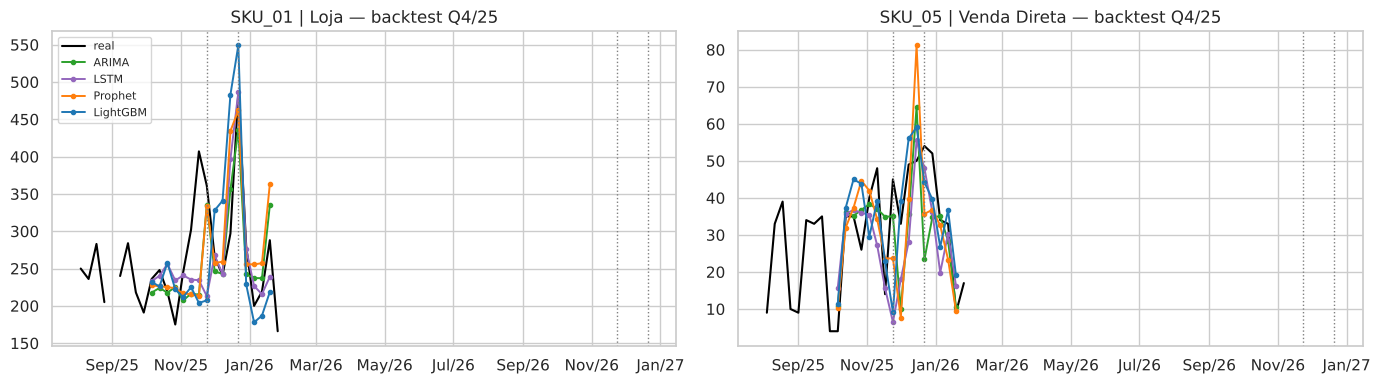

In [75]:
import matplotlib.dates as mdates
# Visual: SKU_01 Loja (o maior) e SKU_05 VD (CAT_A, promocional) no Q4/25
cores = {"ARIMA": "tab:green", "LSTM": "tab:purple", "Prophet": "tab:orange", "LightGBM": "tab:blue"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, s_ in zip(axes, ["SKU_01 | Loja", "SKU_05 | Venda Direta"]):
    hist = base_m[(base_m["serie"] == s_) & base_m["semana"].between("2025-08-01", "2026-02-01")]
    t_ = cmp_q4[cmp_q4["serie"] == s_].sort_values("semana")
    ax.plot(hist["semana"], hist["demanda"], color="black", lw=1.5, label="real")
    for nome, cor in cores.items():
        ax.plot(t_["semana"], t_[MODELOS[nome][0]], color=cor, lw=1.4, marker=".", label=nome)
    for ev_ in semana_do_evento(hist["semana"], "black_friday") + semana_do_evento(hist["semana"], "natal"):
        ax.axvline(ev_, color="grey", ls=":", lw=1)
    ax.set_title(f"{s_} — backtest Q4/25"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b/%y"))
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3.5 Prós e contras: o que os números mostram sobre cada modelo

### LSTM: a surpresa
| Prós | Contras |
|---|---|
| **Empata com o LightGBM em mai–out** (~15%) e é **o melhor no Q4** (~19%, contra ~21,5% do LightGBM) | **Ainda subestima os picos** (viés de ~−15% nas datas comemorativas, igual ao LightGBM): a rede também só viu uma BF útil |
| **Faixa de confiança nativa e mais bem calibrada** que a do LightGBM (~78% de cobertura para 80% prometidos, contra ~70%) | **Variância entre execuções:** cada treino dá um resultado um pouco diferente. Mitiguei com a média de 3 redes, e repetindo com outras sementes o erro variou ~0,3–0,5 p.p. |
| Lê a **sequência** inteira, então capta dinâmicas (aceleração antes da BF, queda pós-Natal) que o LightGBM só vê pelos lags escolhidos à mão | **Explicabilidade:** não há equivalente simples ao SHAP de árvores. Explicar "por que 353 unidades" para o comercial é bem mais difícil |
| Modelo **global** com covariáveis: aproveita padrões de todas as séries, como o LightGBM | **Hiperparâmetros não ajustados** (janela, tamanho, épocas): não há dados para uma validação separada. O resultado bom pode ser em parte sorte de configuração |
| | **Custo e manutenção:** ~10–15× mais lento que o LightGBM (2 min contra 11 s no backtest), depende de PyTorch e exige mais conhecimento para manter em produção |

**Por que ele foi bem, contrariando a expectativa:** a rede recebeu as mesmas três escolhas que fizeram o LightGBM funcionar (modelo global, alvo relativo ao nível recente e o calendário futuro de promoções) e foi mantida pequena para os poucos dados. Uma LSTM "pura", só com o histórico de cada série, provavelmente se comportaria como o ETS. **A lição é que o desenho do problema pesa mais que o algoritmo.**

**Quando eu usaria:** como **candidato forte a substituir ou complementar o LightGBM**, mas só depois de validar com mais histórico (outro Q4) e de resolver a explicação para o negócio.

### ARIMA (com regressores)
| Prós | Contras |
|---|---|
| Aceita variáveis externas (preço, tipos de desconto, eventos), então "sabe" da promoção | Os efeitos são **lineares e iguais** para todas as semanas: um pague-e-leve no Natal tem o mesmo efeito que em março |
| **Faixa de confiança mais bem calibrada** (~81% de cobertura para 80% prometidos em mai–out) | Cada série aprende sozinha: com 1 BF no histórico, o efeito BF de um SKU é estimado com **uma** observação |
| Base teórica sólida, interpretável (coeficientes) | Instável em séries curtas (lançamentos); exige cuidados (regressores sem variação quebram o ajuste) |
| | O mais lento dos quatro, porque a busca automática de ordens roda para 40 séries a cada janela |

**Quando eu usaria:** como baseline estatístico forte e quando a prioridade é a **faixa de confiança** bem calibrada.

### Prophet
| Prós | Contras |
|---|---|
| **Datas comemorativas como "feriados"**: cada evento tem um efeito próprio e explícito. Por isso foi **o melhor no Q4** e quase não erra o tamanho dos picos (viés de ~−2%, contra −16% do LightGBM) | Pior que o LightGBM nas **promoções** (~21% contra ~17,5% em mai–out): os regressores entram de forma aditiva e simples, sem interação com o canal ou com a promoção do irmão |
| Componentes decompostos (tendência, sazonalidade, feriados) fáceis de mostrar a não técnicos | A faixa de 80% cobre só ~64–72%: é otimista |
| Robusto a dados faltantes e mudanças de patamar; pouca configuração | Também ajusta série a série: não "empresta" padrão entre SKUs |
| | Sazonalidade anual com < 2 anos de histórico é pouco confiável (o `auto` a desliga nas séries curtas) |

**Quando eu usaria:** para **planejar picos** (BF, Natal, Dia das Mães) e como modelo de comunicação com o negócio.

### LightGBM: o melhor no ano como um todo
| Prós | Contras |
|---|---|
| **Melhor WAPE em mai–out** (~15,5%) e **melhor nas promoções**, com folga, sobretudo na CAT_A (19% contra 26% dos demais) | **Subestima os picos de Q4** (viés de ~−16% nas datas comemorativas): só viu uma BF útil no treino, e árvores não extrapolam |
| **Modelo global**: aprende com as 40 séries ao mesmo tempo, então o padrão de promoção de um SKU ajuda os outros, inclusive lançamentos | Não traz intervalos nativos: precisa de regressão quantílica + calibração (a faixa crua cobre ~70%) |
| Usa **interações** sem especificá-las (promoção × canal × irmão × evento) e a promoção dos irmãos (canibalização) | Depende de engenharia de features e de cuidado com vazamento (lags ≥ horizonte) |
| Explicável com SHAP e utilizável como **simulador** de cenários de preço e promoção | Associação, não causalidade: para precificar, usar as elasticidades da seção 2 |
| Rápido: um único modelo treina em segundos | "Caixa mais preta" para a área de negócio do que ARIMA ou Prophet (mas bem menos que o LSTM, graças ao SHAP) |


## 3.6 E combinar modelos?

Modelos que erram em lugares diferentes se complementam. A **média geométrica de duas previsões** é a forma mais simples de *ensemble*. Testo o LightGBM com o Prophet (que acerta o tamanho dos picos) e com o LSTM.

In [76]:
for m_ in (cmp_ma, cmp_q4):
    m_["Combinação"] = np.sqrt(m_["p50"] * m_["Prophet"])
    m_["Comb_LSTM"] = np.sqrt(m_["p50"] * m_["LSTM"])
MODELOS["LightGBM + Prophet"] = ("Combinação", None, None)
MODELOS["LightGBM + LSTM"] = ("Comb_LSTM", None, None)
(pd.concat({"mai–out/26": placar(cmp_ma), "Q4/25": placar(cmp_q4)}, axis=1).round(3)
   .loc[["LightGBM", "LSTM", "Prophet", "LightGBM + Prophet", "LightGBM + LSTM"]]
   .drop(columns=[("mai–out/26", "cobertura faixa 80%"), ("Q4/25", "cobertura faixa 80%")]))

mai–out/26                                                                         Q4/25                                                \
                         WAPE   viés WAPE promoção WAPE datas comemorativas viés datas comemorativas   WAPE   viés WAPE promoção WAPE datas comemorativas   
modelo                                                                                                                                                      
LightGBM                0.154 -0.003         0.173                    0.149                    0.022  0.215 -0.057         0.221                    0.256   
LSTM                    0.152  0.000         0.167                    0.153                   -0.007  0.189 -0.068         0.216                    0.230   
Prophet                 0.178 -0.009         0.206                    0.194                   -0.022  0.209 -0.011         0.250                    0.217   
LightGBM + Prophet      0.157 -0.009         0.178                    0.160                   -0.006  0.191 -0.048         0.196                    0.219   
LightGBM + LSTM         0.146 -0.003         0.159                    0.146                    0.006  0.192 -0.065         0.203                    0.238   

                                             
                   viés datas comemorativas  
modelo                                       
LightGBM                             -0.159  
LSTM                                 -0.142  
Prophet                              -0.021  
LightGBM + Prophet                   -0.115  
LightGBM + LSTM                      -0.153

**Leitura:**
- **LightGBM + LSTM** é a melhor combinação no ano (~14,7% em mai–out, o menor erro de todo o notebook): as duas abordagens erram em semanas diferentes.
- **No Q4, três opções empatam** perto de 19%: LSTM sozinho, LightGBM + Prophet e LightGBM + LSTM. Entre elas, a **LightGBM + Prophet erra menos o tamanho dos picos** (viés de ~−11% nas datas comemorativas, contra ~−15%), graças ao componente de feriados do Prophet.
- Os ganhos são de 1 a 2 pontos percentuais, medidos num único Q4. São indícios fortes, não certezas.

## 3.7 Escolha

| Uso | Modelo | Por quê |
|---|---|---|
| **Previsão do dia a dia e simulação de promoções** | **LightGBM** | Menor erro no ano, melhor nas promoções, explicável com SHAP, serve de simulador |
| **Semanas de pico (Q4, datas comemorativas)** | **LightGBM + Prophet** (média) | Empata com as melhores opções no Q4 e é a que menos subestima os picos, sem perder a leitura de promoções |
| **Referência/validação** | ARIMA | Faixa mais bem calibrada: bom "segundo parecer" para o planejador |
| **Candidato a próxima versão** | LSTM, ou LightGBM + LSTM | Tão preciso quanto o LightGBM e melhor no Q4; combinado com ele, dá o menor erro do notebook. Falta resolver a explicação para o negócio e validar em mais de um Q4 |

Na seção 4, a previsão final usa o LightGBM (explicação, simulador e semáforo dependem dele), e a tabela de entrega mostra também a **combinação**, que é a referência para a semana de Black Friday.

### 3.7.1 Calibrando a faixa do LightGBM
A faixa P10–P90 crua do LightGBM cobre ~70% das semanas, menos que os 80% prometidos. Uma **correção conformal** mede, no backtest, o quanto a demanda real "escapou" da faixa e a alarga na medida certa. Uso uma folga para semanas comuns e outra, maior, para o Q4 e as datas comemorativas.

In [77]:
def escore_conformal(g):
    ly, l10, l90 = np.log1p(g["demanda"]), np.log1p(g["p10"]), np.log1p(g["p90"])
    return np.maximum(l10 - ly, ly - l90)

def folga_conformal(g, cobertura=0.80):
    s = escore_conformal(g)
    n = len(s)
    return np.quantile(s, min(1.0, np.ceil((n + 1) * cobertura) / n))

def aplicar_folga(g, q):
    g = g.copy()
    g["p10_cal"] = np.expm1(np.log1p(g["p10"]) - q).clip(lower=0)
    g["p90_cal"] = np.expm1(np.log1p(g["p90"]) + q)
    return g


Q_CONFORMAL = folga_conformal(cmp_ma)
Q_PICO = folga_conformal(pd.concat([cmp_q4, cmp_ma[cmp_ma["tipo_semana"] == "data comemorativa"]]))
for nome_, m_, q_ in [("mai–out (folga comum)", cmp_ma, Q_CONFORMAL), ("Q4 (folga de pico)", cmp_q4, Q_PICO)]:
    c_ = aplicar_folga(m_, q_)
    print(f"{nome_}: cobertura antes {((m_.demanda >= m_.p10) & (m_.demanda <= m_.p90)).mean():.0%}"
          f" → depois {((c_.demanda >= c_.p10_cal) & (c_.demanda <= c_.p90_cal)).mean():.0%}")
bt = aplicar_folga(cmp_ma, Q_CONFORMAL)     # usado no semáforo (seção 4)

mai–out (folga comum): cobertura antes 70% → depois 80%
Q4 (folga de pico): cobertura antes 57% → depois 77%


*Ressalva:* as coberturas "depois" são medidas na própria amostra usada para calibrar, então são uma checagem de consistência, não uma validação independente.

---
# 4. Previsão final, explicabilidade e semáforo de confiança

## 4.1 Modelo final e previsão das próximas 4 semanas

Treino o **LightGBM** com **toda** a história e prevejo de 02/11 a 23/11/2026. Como a janela é de Q4, também calculo o **Prophet** e a **combinação dos dois**, que foi a melhor no backtest do Q4 (seção 3.6). A última semana é a da **Black Friday** (27/11), o que é ótimo para demonstrar o modelo.

**Cenário base:** sem promoção e com preço regular. Como as features de promoção são planejadas pelo time de RGM, o modelo também serve de **simulador** (seção 4.4).

In [78]:
ultima = d["semana"].max()
futuras = pd.date_range(ultima + pd.Timedelta(weeks=1), periods=H, freq="7D")
modelo_series = d.drop_duplicates(["sku_id", "canal"])[["sku_id", "canal", "categoria_id", "subcategoria_id", "serie"]]
fut = modelo_series.merge(pd.DataFrame({"semana": futuras}), how="cross")
fut["preco_tabela"] = fut["serie"].map(d.groupby("serie")["preco_tabela"].first())
fut["preco_regular"] = fut["serie"].map(preco_regular)
fut["log_preco_rel"] = np.log(fut["preco_regular"] / fut["preco_tabela"])
fut["desconto_modelo"] = 100 * (1 - fut["preco_regular"] / fut["preco_tabela"])
for f in FLAGS:
    fut[f] = False
fut[["n_mecanicas", "irmao_promo", "outra_sub_promo"]] = 0
fut[["em_promo", "teve_ruptura"]] = False
fut = features_calendario(fut)

completo = pd.concat([d, fut], ignore_index=True)
base_f = construir_features(completo)
base_f["y"] = np.log1p(base_f["demanda"]) - np.log1p(base_f["media_8s"])   # mesmo alvo relativo do backtest
treino_final = base_f[base_f["semana"] <= ultima]
treino_final = treino_final[treino_final["y"].notna() & treino_final["lag_4"].notna()]
modelos_finais = treinar(treino_final)

X_fut = base_f[base_f["semana"] > ultima].copy()
X_fut[["p10", "p50", "p90"]] = prever(modelos_finais, X_fut)
X_fut["semana_evento"] = X_fut[ev_cols].any(axis=1)
pico = X_fut["semana_evento"] | (X_fut["semana"].dt.quarter == 4)
X_fut = aplicar_folga(X_fut, np.where(pico, Q_PICO, Q_CONFORMAL))   # faixa mais larga no Q4 e em datas comemorativas

# Prophet final: cada série ajustada com toda a história, prevendo as 4 semanas com o mesmo cenário (sem promoção)
prophet_fut = []
for serie, g in base_f.groupby("serie"):
    tr = g[g["semana"] <= ultima].assign(y=np.log1p(g["demanda_interp"]))
    fu = g[g["semana"] > ultima]
    m = Prophet(yearly_seasonality="auto", weekly_seasonality=False, daily_seasonality=False,
                holidays=FERIADOS, uncertainty_samples=0)
    for c_ in REG_PROPHET:
        m.add_regressor(c_)
    m.fit(tr[["semana", "y"] + REG_PROPHET].rename(columns={"semana": "ds"}).astype({c_: float for c_ in REG_PROPHET}))
    fc = m.predict(fu[["semana"] + REG_PROPHET].rename(columns={"semana": "ds"}).astype({c_: float for c_ in REG_PROPHET}))
    prophet_fut.append(pd.Series(np.expm1(fc["yhat"].values).clip(0), index=fu.index))
X_fut["prophet"] = pd.concat(prophet_fut)
X_fut["combinacao"] = np.sqrt(X_fut["p50"] * X_fut["prophet"])
print(X_fut.groupby("semana")[["p10_cal", "p50", "p90_cal", "prophet", "combinacao"]].sum().round(0)
        .rename(columns={"p10_cal": "mínimo provável", "p50": "LightGBM", "p90_cal": "máximo provável",
                         "prophet": "Prophet", "combinacao": "LightGBM + Prophet"}))

            mínimo provável  LightGBM  máximo provável  Prophet  LightGBM + Prophet
semana                                                                             
2026-11-02           1332.0    1860.0           2231.0   1557.0              1698.0
2026-11-09           1338.0    1881.0           2326.0   1559.0              1708.0
2026-11-16           1328.0    1856.0           2452.0   1560.0              1697.0
2026-11-23           1368.0    2495.0           2969.0   2658.0              2566.0


## 4.2 Explicabilidade global: o que o modelo usa para prever?

Uso **SHAP**, que distribui cada previsão entre as features de forma justa (valores de Shapley, da teoria dos jogos). Para um público não técnico, **agrupo as 30+ features em 6 "motivos"** fáceis de entender.

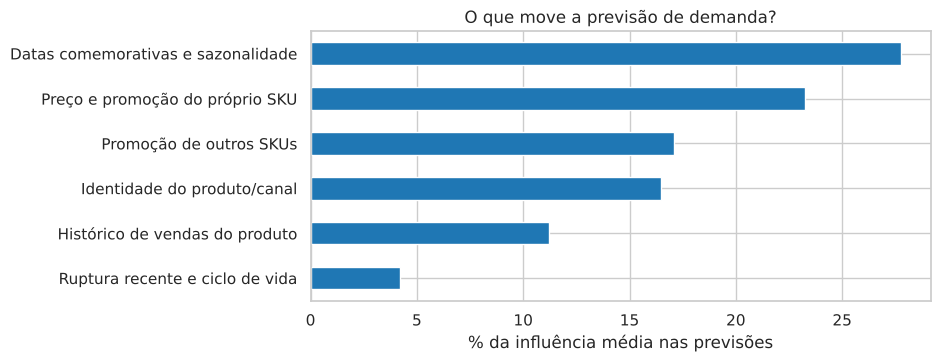

In [79]:
import shap

GRUPOS = {
    "Histórico de vendas do produto": ["lag_4", "lag_5", "lag_6", "lag_8", "lag_13", "lag_52", "media_8s", "dp_8s", "tendencia"],
    "Identidade do produto/canal": CATS,
    "Datas comemorativas e sazonalidade": ev_cols + ["mes", "semana_ano"],
    "Preço e promoção do próprio SKU": ["log_preco_rel", "desconto_modelo", "n_mecanicas"] + FLAGS,
    "Promoção de outros SKUs": ["irmao_promo", "outra_sub_promo"],
    "Ruptura recente e ciclo de vida": ["ruptura_recente", "idade_semanas"],
}
assert sorted(sum(GRUPOS.values(), [])) == sorted(FEATURES)

explainer = shap.TreeExplainer(modelos_finais["p50"])
amostra = treino_final.sample(1500, random_state=0)
sv = pd.DataFrame(explainer.shap_values(amostra[FEATURES]), columns=FEATURES, index=amostra.index)
sv_grupo = pd.DataFrame({g: sv[cols].sum(axis=1) for g, cols in GRUPOS.items()})

imp = sv_grupo.abs().mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 3.5))
(100 * imp / imp.sum()).plot.barh(ax=ax, color="tab:blue")
ax.set_xlabel("% da influência média nas previsões")
ax.set_title("O que move a previsão de demanda?")
plt.show()

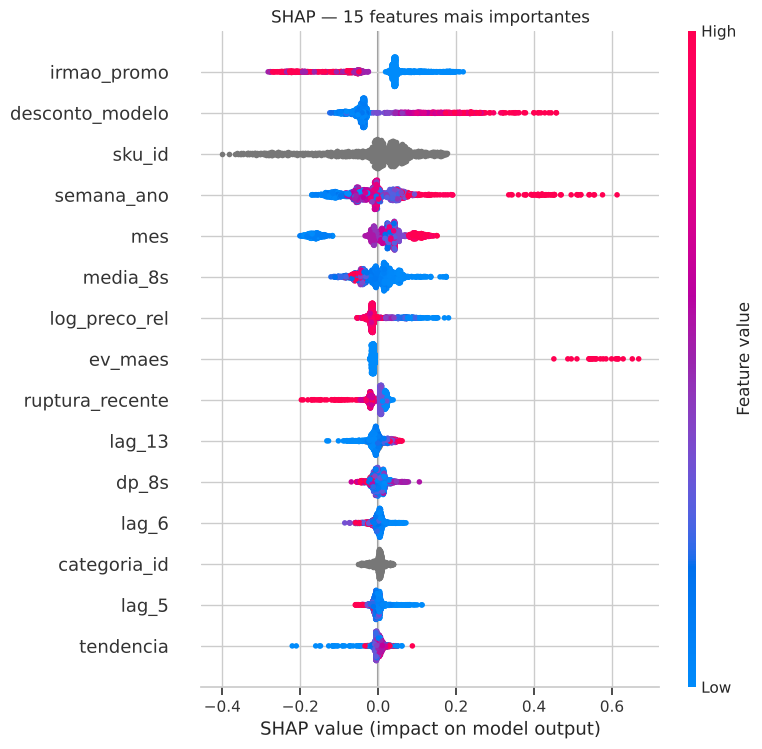

In [80]:
# Detalhe técnico (para leitores técnicos): importância por feature individual
shap.summary_plot(sv.values, amostra[FEATURES], max_display=15, show=False)
plt.title("SHAP — 15 features mais importantes"); plt.show()

**Leitura:** como o alvo é relativo ao nível recente, o SHAP explica **por que esta semana vai fugir da média das últimas semanas**. O histórico (tendência, mesma época do ano anterior) e a identidade do produto ajustam o patamar, e o calendário e a promoção explicam os picos. É exatamente o que a EDA mostrou. O gráfico de pontos confirma direções coerentes com o negócio: preço relativo menor (mais desconto) → previsão maior; semana de evento → previsão maior; irmão em promoção → previsão menor.

> **Validar a coerência do SHAP com a EDA** é um argumento forte: o modelo aprendeu os mesmos padrões que a econometria encontrou, então não está "decorando ruído".

## 4.3 Explicabilidade local: uma frase por previsão

Como o modelo prevê o log da razão sobre a média recente, cada contribuição SHAP vira um **fator multiplicativo** sobre essa média: `exp(SHAP)`. Isso permite uma frase do tipo: *"este produto vendeu em média ~260 un. nas últimas semanas; a Black Friday soma +52%..."*.

In [81]:
base_valor = np.expm1(explainer.expected_value)
sv_fut = pd.DataFrame(explainer.shap_values(X_fut[FEATURES]), columns=FEATURES, index=X_fut.index)
sv_fut_g = pd.DataFrame({g: sv_fut[cols].sum(axis=1) for g, cols in GRUPOS.items()})

def explicar(idx, top=3):
    r = X_fut.loc[idx]
    contrib = sv_fut_g.loc[idx]
    partida = r["media_8s"]                         # ponto de partida: média das últimas 8 semanas conhecidas
    linhas = [f"**{r['serie']} — semana de {r['semana']:%d/%m}**: previsão de **{r['p50']:.0f} un.** "
              f"(faixa provável {r['p10_cal']:.0f}–{r['p90_cal']:.0f})",
              f"- Média recente deste produto/canal: ~{partida:.0f} un./semana. Principais ajustes desta semana:"]
    for g, v in contrib.reindex(contrib.abs().sort_values(ascending=False).index)[:top].items():
        linhas.append(f"- {g}: {'+' if v > 0 else '−'}{100 * abs(np.exp(v) - 1):.0f}%")
    return "\n".join(linhas)

from IPython.display import Markdown, display
for s, sem in [("SKU_01 | Loja", futuras[-1]), ("SKU_05 | Venda Direta", futuras[-1]), ("SKU_02 | Loja", futuras[0])]:
    idx = X_fut.index[(X_fut["serie"] == s) & (X_fut["semana"] == sem)][0]
    display(Markdown(explicar(idx)))

**SKU_01 | Loja — semana de 23/11**: previsão de **349 un.** (faixa provável 184–414)
- Média recente deste produto/canal: ~222 un./semana. Principais ajustes desta semana:
- Datas comemorativas e sazonalidade: +53%
- Identidade do produto/canal: +8%
- Preço e promoção do próprio SKU: −7%

**SKU_05 | Venda Direta — semana de 23/11**: previsão de **37 un.** (faixa provável 16–47)
- Média recente deste produto/canal: ~25 un./semana. Principais ajustes desta semana:
- Datas comemorativas e sazonalidade: +54%
- Promoção de outros SKUs: +14%
- Preço e promoção do próprio SKU: −9%

**SKU_02 | Loja — semana de 02/11**: previsão de **16 un.** (faixa provável 11–18)
- Média recente deste produto/canal: ~14 un./semana. Principais ajustes desta semana:
- Datas comemorativas e sazonalidade: +15%
- Preço e promoção do próprio SKU: −6%
- Promoção de outros SKUs: +5%

*Como ler um ajuste negativo de "preço e promoção" sem promoção planejada:* o ponto de partida é a média das últimas semanas, que pode **incluir** semanas promocionais. Uma semana sem promoção tende, então, a ficar abaixo dessa média. Vale antecipar essa pergunta na apresentação.

## 4.4 Simulador de cenários: o modelo a serviço do RGM

Como preço e promoção são *inputs*, dá para perguntar: **"e se fizermos pague-e-leve com 25% na Black Friday?"**

*Ressalva:* o simulador considera o efeito no próprio SKU. O efeito nos irmãos (canibalização, seção 2.6) deveria ser somado para a decisão final, que é avaliada no nível da subcategoria.

In [82]:
def simular(serie, semana, mecanica, desconto_pct):
    base_row = X_fut[(X_fut["serie"] == serie) & (X_fut["semana"] == semana)].copy()
    cen = base_row.copy()
    cen[mecanica] = True
    cen["n_mecanicas"] = 1
    cen["desconto_modelo"] = desconto_pct
    cen["log_preco_rel"] = np.log(1 - desconto_pct / 100)
    p_base = prever(modelos_finais, base_row).iloc[0]
    p_cen = prever(modelos_finais, cen).iloc[0]
    preco_cen = base_row["preco_tabela"].iloc[0] * (1 - desconto_pct / 100)
    c_unit = custo[serie]
    return pd.Series({
        "demanda base": p_base["p50"], "demanda c/ promo": p_cen["p50"],
        "uplift %": 100 * (p_cen["p50"] / p_base["p50"] - 1),
        "lucro bruto base": (base_row["preco_regular"].iloc[0] - c_unit) * p_base["p50"],
        "lucro bruto c/ promo": (preco_cen - c_unit) * p_cen["p50"],
    }, name=f"{serie} · {mecanica.replace('flag_', '')} {desconto_pct}%")

bf = futuras[-1]
pd.DataFrame([
    simular("SKU_05 | Venda Direta", bf, "flag_pague_e_leve", 25),   # CAT_A (elástica)
    simular("SKU_05 | Venda Direta", bf, "flag_desconto_direto", 25),
    simular("SKU_09 | Venda Direta", bf, "flag_pague_e_leve", 25),   # CAT_B (inelástica)
    simular("SKU_09 | Venda Direta", bf, "flag_desconto_direto", 25),
]).round(1)

,demanda base,demanda c/ promo,uplift %,lucro bruto base,lucro bruto c/ promo
SKU_05 | Venda Direta · pague_e_leve 25%,37.0,56.9,53.6,944.7,801.0
SKU_05 | Venda Direta · desconto_direto 25%,37.0,55.1,49.0,944.7,777.0
SKU_09 | Venda Direta · pague_e_leve 25%,39.0,53.2,36.5,1628.7,1011.1
SKU_09 | Venda Direta · desconto_direto 25%,39.0,50.8,30.3,1628.7,965.5


## 4.5 Semáforo de confiabilidade

O objetivo é dizer a quem planeja **quanto confiar** em cada número, sem exigir conhecimento de estatística. O semáforo conta **sinais de alerta**:

| Sinal de alerta | Pergunta que responde | Limite |
|---|---|---|
| **Faixa larga** ((P90 − P10) ÷ P50) | "Quão incerta é *esta* previsão específica?" | > 50% da previsão |
| **Erro histórico alto** (WAPE da série no backtest) | "O modelo costuma acertar este produto?" | > 18% |
| **Vendas voláteis** (desvio-padrão ÷ média das últimas 8 semanas) | "O produto anda instável?" | > 35% |
| **Histórico curto** | "Há dados para aprender?" | < 26 semanas (conta como 2 alertas) |
| **Data comemorativa** | "É um pico para o qual há pouco histórico?" | semana de BF, Natal, Mães etc. (seção 3.5) |

O semáforo é **binário** (azul e vermelho, cores que também funcionam para daltônicos):

- 🔵 **Confiável:** 0 ou 1 alerta. *Pode usar o número direto.*
- 🔴 **Atenção:** 2 ou mais alertas. *Planeje pela faixa, não pelo número, e revise com o time comercial.*

**Por que dois níveis e não três:** numa primeira versão havia um nível intermediário (1 alerta), mas no backtest ele errava praticamente o mesmo que o nível sem alertas (~13–14%). Três cores que os dados não separam só confundem quem usa. **Como o limite foi escolhido:** testei o corte em 1 e em 2 alertas; com corte em 1, 64% das previsões ficariam vermelhas (alarme demais); com corte em 2, o vermelho cobre ~40% e concentra o erro. Ou seja: *o semáforo não é opinião, ele foi validado fora da amostra.*

In [83]:
wape_serie = bt.groupby("serie").apply(lambda g: wape(g["demanda"], g["p50"])).rename("erro_hist")
idade_atual = base_f[base_f["semana"] == ultima].set_index("serie")["idade_semanas"] + 1

def semaforo(erro, largura, cv, idade, evento=False):
    alertas = (largura > 0.50) + (erro > 0.18) + (cv > 0.35) + 2 * (idade < 26) + int(evento)
    return "🔵 confiável" if alertas <= 1 else "🔴 atenção"

# Validação no backtest: usando o erro das janelas ANTERIORES de cada série (sem olhar o futuro)
bt["erro_abs"] = (bt["demanda"] - bt["p50"]).abs()
ag = (bt.groupby(["serie", "origem"]).agg(ea=("erro_abs", "sum"), y=("demanda", "sum"))
        .reset_index().sort_values(["serie", "origem"]))
ag["erro_hist_passado"] = ((ag.groupby("serie")["ea"].cumsum() - ag["ea"])
                           / (ag.groupby("serie")["y"].cumsum() - ag["y"]).replace(0, np.nan))
bt = bt.drop(columns="erro_hist_passado", errors="ignore").merge(ag[["serie", "origem", "erro_hist_passado"]], on=["serie", "origem"])
bt["largura"] = (bt["p90_cal"] - bt["p10_cal"]) / bt["p50"]
v = bt.dropna(subset=["erro_hist_passado"]).copy()
v["cv"] = v["dp_8s"] / v["media_8s"]
v["semaforo"] = [semaforo(e, l, c, i, ev) for e, l, c, i, ev in
                 zip(v["erro_hist_passado"], v["largura"], v["cv"], v["idade_semanas"], v[ev_cols].any(axis=1))]
(v.groupby("semaforo").apply(lambda g: pd.Series({"% das previsões": len(g) / len(v),
                                                   "WAPE realizado": wape(g["demanda"], g["p50"]),
                                                   "cobertura da faixa": ((g["demanda"] >= g["p10_cal"]) & (g["demanda"] <= g["p90_cal"])).mean()}))
   .round(3))

,% das previsões,WAPE realizado,cobertura da faixa
semaforo,,,
🔴 atenção,0.392,0.193,0.717
🔵 confiável,0.608,0.131,0.856


O semáforo **separa as previsões**: no vermelho (~40% dos casos), o erro realizado é ~19% e a faixa acerta ~72% das vezes; no azul (~60%), o erro cai para ~13% e a faixa acerta ~86%. Ou seja, quando o semáforo diz "atenção", a previsão de fato erra ~1,5× mais.

**Na previsão de novembro, toda a semana de Black Friday fica vermelha**, por desenho: é data comemorativa (alerta) e a faixa é mais larga. Esse é o comportamento certo, dado que o backtest do Q4 mostrou que o LightGBM subestima picos (seção 3.5). Para a semana da BF, a recomendação é usar a coluna **"previsão p/ picos"** (LightGBM + Prophet) e planejar o estoque olhando o **máximo provável**.

In [84]:
X_fut["erro_hist"] = X_fut["serie"].map(wape_serie)
X_fut["largura"] = (X_fut["p90_cal"] - X_fut["p10_cal"]) / X_fut["p50"]
X_fut["idade"] = X_fut["serie"].map(idade_atual)
X_fut["cv"] = X_fut["dp_8s"] / X_fut["media_8s"]
X_fut["confiança"] = [semaforo(e, l, c, i, ev) for e, l, c, i, ev in
                      zip(X_fut["erro_hist"], X_fut["largura"], X_fut["cv"], X_fut["idade"], X_fut["semana_evento"])]

entrega = (X_fut[["serie", "categoria_id", "semana", "p50", "combinacao", "p10_cal", "p90_cal", "erro_hist", "confiança"]]
           .rename(columns={"p50": "previsão", "combinacao": "previsão p/ picos (LGBM+Prophet)",
                            "p10_cal": "mínimo provável", "p90_cal": "máximo provável", "erro_hist": "erro histórico"})
           .assign(semana=lambda x: x["semana"].dt.strftime("%d/%m"))
           .round({"previsão": 0, "previsão p/ picos (LGBM+Prophet)": 0, "mínimo provável": 0, "máximo provável": 0, "erro histórico": 2}))
print(entrega["confiança"].value_counts())
entrega[entrega["semana"] == f"{bf:%d/%m}"].sort_values("previsão", ascending=False)

confiança
🔴 atenção      96
🔵 confiável    64
Name: count, dtype: int64


,serie,categoria_id,semana,previsão,previsão p/ picos (LGBM+Prophet),mínimo provável,máximo provável,erro histórico,confiança
3739,SKU_01 | Venda Direta,CAT_B,23/11,351.0,382.0,191.0,417.0,0.18,🔴 atenção
3735,SKU_01 | Loja,CAT_B,23/11,349.0,362.0,184.0,414.0,0.11,🔴 atenção
3807,SKU_10 | Loja,CAT_B,23/11,234.0,249.0,130.0,271.0,0.18,🔴 atenção
3811,SKU_10 | Venda Direta,CAT_B,23/11,122.0,145.0,69.0,142.0,0.16,🔴 atenção
3871,SKU_18 | Loja,CAT_C,23/11,91.0,94.0,55.0,107.0,0.15,🔴 atenção
3835,SKU_13 | Venda Direta,CAT_C,23/11,89.0,72.0,51.0,110.0,0.16,🔴 atenção
3891,SKU_20 | Venda Direta,CAT_A,23/11,82.0,85.0,49.0,94.0,0.11,🔴 atenção
3783,SKU_07 | Loja,CAT_B,23/11,70.0,72.0,39.0,82.0,0.13,🔴 atenção
3787,SKU_07 | Venda Direta,CAT_B,23/11,60.0,64.0,35.0,70.0,0.12,🔴 atenção
3767,SKU_05 | Loja,CAT_A,23/11,58.0,64.0,25.0,79.0,0.30,🔴 atenção


In [85]:
entrega.to_csv(DIR_SAIDAS / "previsao_4_semanas.csv", index=False)
print("Tabela de previsões salva em outputs/previsao_4_semanas.csv")

Tabela de previsões salva em outputs/previsao_4_semanas.csv


---
## 4.6 Explicando o LSTM: DeepSHAP e alternativas

O SHAP do LightGBM (seção 4.2) usa o **TreeSHAP**, que calcula os valores de Shapley **exatos** aproveitando a estrutura das árvores. Numa rede neural não há árvores, e calcular Shapley exato exigiria testar todas as combinações das ~240 entradas do LSTM (16 semanas × 12 colunas + 4 × 10 do futuro + 4 estáticas): 2²⁴⁰ combinações, o que é impossível. Por isso existem **aproximações**:

| Método | Como funciona | Garantia de soma (aditividade) | Custo |
|---|---|---|---|
| **DeepSHAP** (`shap.DeepExplainer`) | Combina o **DeepLIFT** (propaga, camada a camada, a diferença entre a entrada e uma referência) com uma média sobre várias referências (o "fundo") | Exata **só** se cada operação da rede tiver regra de propagação. Funções da LSTM (sigmoides e produtos nas "portas" de memória) **não são totalmente suportadas** no PyTorch | Rápido: 1 passagem para trás por referência |
| **Expected Gradients** (`shap.GradientExplainer`) | Integra os **gradientes** ao longo de caminhos entre referências do fundo e a entrada (extensão dos *Integrated Gradients*) | **Aproximada**, mas converge para a soma correta com mais amostras | Moderado: centenas a milhares de gradientes |
| **KernelSHAP** | Trata o modelo como caixa-preta e ajusta uma regressão local sobre combinações de entradas "ligadas/desligadas" | Aproximada | Muito caro com ~240 entradas |

**Conceito central, o "fundo" (*background*):** o SHAP sempre explica a diferença **em relação a uma referência**: "por que esta previsão é diferente da previsão típica?". Aqui o fundo são 100 janelas de treino sorteadas. Um efeito importante disso: uma variável que vale **zero** na previsão (ex.: "não houve Natal nas últimas 16 semanas") pode receber contribuição, porque no fundo ela às vezes vale 1. **Mudar o fundo muda a explicação.**

**Abaixo:** treino o LSTM final (toda a história) e explico a mesma previsão da seção 4.3, a do **SKU_01 na Loja na semana da Black Friday**, com os dois métodos.

In [86]:
import shap
for c_ in EX_LSTM:
    base_f[c_] = base_f[c_].astype(float)
SERIES_FINAL = preparar_series(base_f.assign(demanda_interp=base_f["demanda_interp"].fillna(1.0)), H)  # futuro: só covariáveis entram
redes_finais, _ = treinar_lstm(SERIES_FINAL, futuras[0], H)
prev_lstm = prever_lstm(redes_finais, SERIES_FINAL, futuras[0], H)

class SaidaBF(nn.Module):
    """P50 (em log, relativo à média recente) da 4ª semana à frente (BF), média das 3 redes."""
    def __init__(self, redes):
        super().__init__(); self.redes = nn.ModuleList(redes)
    def forward(self, passado, futuro, estatico):
        return torch.stack([r(passado, futuro, estatico)[:, 3, 1] for r in self.redes]).mean(0).unsqueeze(1)
modelo_bf = SaidaBF(redes_finais).eval()

# entrada a explicar
s_bf = SERIES_FINAL["SKU_01 | Loja"]
t_bf = int((s_bf["semana"] < np.datetime64(futuras[0])).sum())
pas, fut_ex, nivel_bf = _janela(s_bf, t_bf, H)
x_bf = [torch.tensor(pas[None]), torch.tensor(fut_ex[None]), torch.tensor(s_bf["est"][None])]

# fundo: 100 janelas de treino sorteadas
rng = np.random.default_rng(0); nomes_s = list(SERIES_FINAL); fundo = ([], [], [])
for _ in range(100):
    ss = SERIES_FINAL[nomes_s[rng.integers(len(nomes_s))]]
    nh = int((ss["semana"] < np.datetime64(futuras[0])).sum())
    a_, b_, _ = _janela(ss, int(rng.integers(8, nh - H + 1)), H)
    fundo[0].append(a_); fundo[1].append(b_); fundo[2].append(ss["est"])
fundo = [torch.tensor(np.array(z)) for z in fundo]

with torch.no_grad():
    f_x, f_fundo = modelo_bf(*x_bf).item(), modelo_bf(*fundo).mean().item()
print(f"Previsão LSTM para SKU_01 | Loja em {futuras[3]:%d/%m}: {np.expm1(f_x + nivel_bf):.0f} un. "
      f"(média recente {np.expm1(nivel_bf):.0f} un.)")
print(f"O que o SHAP precisa repartir: f(x) − E[f(fundo)] = {f_x - f_fundo:.3f} (em log)")

Previsão LSTM para SKU_01 | Loja em 23/11: 335 un. (média recente 222 un.)
O que o SHAP precisa repartir: f(x) − E[f(fundo)] = 0.435 (em log)


In [87]:
resultados_xai = {}
sv_deep = shap.DeepExplainer(modelo_bf, fundo).shap_values(x_bf, check_additivity=False)
resultados_xai["DeepSHAP"] = [np.array(v).squeeze() for v in sv_deep]
for ns in [200, 2000]:
    sv_g = shap.GradientExplainer(modelo_bf, fundo).shap_values(x_bf, nsamples=ns, rseed=0)
    resultados_xai[f"Expected Gradients ({ns} amostras)"] = [np.array(v).squeeze() for v in sv_g]
pd.DataFrame({k: {"soma das contribuições": sum(v.sum() for v in sv),
                  "deveria somar": f_x - f_fundo,
                  "erro de aditividade": sum(v.sum() for v in sv) - (f_x - f_fundo)}
              for k, sv in resultados_xai.items()}).T.round(3)

,soma das contribuições,deveria somar,erro de aditividade
DeepSHAP,0.360,0.435,-0.074
Expected Gradients (200 amostras),0.430,0.435,-0.004
Expected Gradients (2000 amostras),0.438,0.435,0.003


**Leitura:** o DeepSHAP "perde" parte do total (a soma fica abaixo do que deveria), porque as operações internas da LSTM não têm regra exata de propagação. Por isso, por padrão, o pacote **recusa** o resultado (precisei desligar a checagem com `check_additivity=False`). O Expected Gradients chega mais perto quanto mais amostras usa. **Para uma LSTM em PyTorch, eu usaria o Expected Gradients e reportaria o erro de aditividade junto.**

In [88]:
cols_passado = ["demanda (relativa)"] + EX_LSTM + ["preenchimento"]
def agrupar_lstm(sv):
    pv, fv, ev = sv
    i_ev = [EX_LSTM.index(c) for c in EX_LSTM if c.startswith("ev_")]
    i_pr = [EX_LSTM.index(c) for c in EX_LSTM if not c.startswith("ev_")]
    return pd.Series({
        "Histórico de vendas (16 semanas)": pv[:, 0].sum(),
        "Preço/promoção passados": pv[:, 1:1 + len(EX_LSTM)][:, i_pr].sum(),
        "Eventos no passado recente": pv[:, 1:1 + len(EX_LSTM)][:, i_ev].sum() + pv[:, -1].sum(),
        "Datas comemorativas à frente": fv[:, i_ev].sum(),
        "Preço/promoção planejados": fv[:, i_pr].sum(),
        "Canal e categoria": ev.sum(),
    })

xai = pd.DataFrame({k: agrupar_lstm(v) for k, v in resultados_xai.items()})
# comparação com o SHAP do LightGBM para a MESMA previsão (seção 4.3)
idx_lgbm = X_fut.index[(X_fut["serie"] == "SKU_01 | Loja") & (X_fut["semana"] == futuras[3])][0]
lgbm_eventos = sv_fut_g.loc[idx_lgbm, "Datas comemorativas e sazonalidade"]
print("Efeito multiplicativo de cada grupo (exp(SHAP) − 1):")
tab_xai = (np.exp(xai) - 1).mul(100).round(1).astype(str) + "%"
tab_xai.loc["(LightGBM) Datas comemorativas e sazonalidade", :] = f"{100 * (np.exp(lgbm_eventos) - 1):.1f}%"
tab_xai

Efeito multiplicativo de cada grupo (exp(SHAP) − 1):


,DeepSHAP,Expected Gradients (200 amostras),Expected Gradients (2000 amostras)
Histórico de vendas (16 semanas),-3.0%,3.9%,3.5%
Preço/promoção passados,-1.7%,0.4%,0.2%
Eventos no passado recente,10.9%,12.4%,11.5%
Datas comemorativas à frente,43.7%,41.1%,41.9%
Preço/promoção planejados,-3.0%,-4.7%,-3.4%
Canal e categoria,-2.6%,-2.5%,-2.3%
(LightGBM) Datas comemorativas e sazonalidade,53.0%,53.0%,53.0%


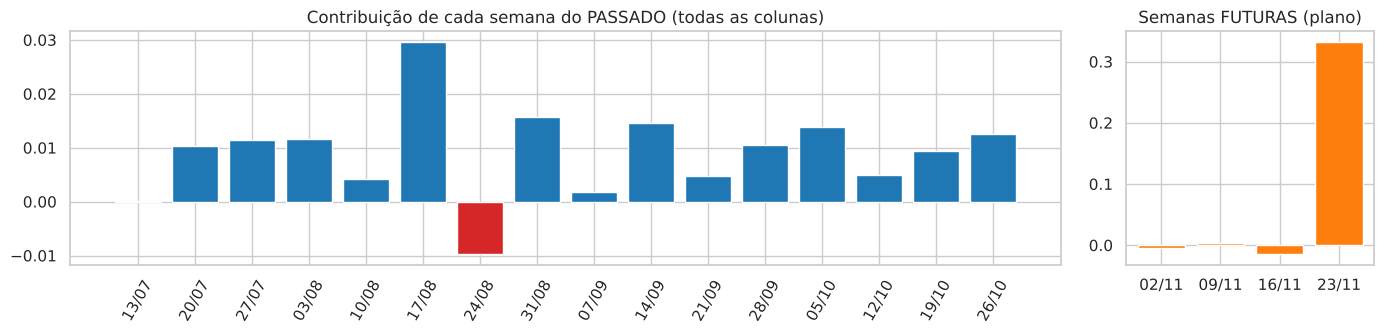

In [89]:
# Onde, no tempo, o LSTM "olha"? Contribuição por semana do passado e do futuro (Expected Gradients, 2000 amostras)
pv, fv, _ = resultados_xai["Expected Gradients (2000 amostras)"]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), gridspec_kw={"width_ratios": [4, 1]})
semanas_p = pd.date_range(end=ultima, periods=L_JANELA, freq="7D")
axes[0].bar(semanas_p.strftime("%d/%m"), pv.sum(axis=1), color=np.where(pv.sum(axis=1) > 0, "tab:blue", "tab:red"))
axes[0].set_title("Contribuição de cada semana do PASSADO (todas as colunas)"); axes[0].tick_params(axis="x", rotation=60)
axes[1].bar(futuras.strftime("%d/%m"), fv.sum(axis=1), color="tab:orange")
axes[1].set_title("Semanas FUTURAS (plano)")
plt.tight_layout(); plt.show()

**O que a explicação do LSTM mostra:**
- **O principal motivo do pico é "data comemorativa à frente"** (+44% a +46%, conforme o método), próximo dos ~+52% que o SHAP do LightGBM atribui ao calendário (o grupo do LightGBM inclui também mês e semana do ano). Dois modelos muito diferentes **concordam sobre o porquê** da previsão, e isso é um argumento forte de que ambos aprenderam um padrão real.
- Na linha do tempo, quase toda a contribuição do **futuro** está na semana da BF. No passado, as 16 semanas contribuem pouco e de forma espalhada: com o alvo relativo, o histórico serve mais para "calibrar o patamar" do que para empurrar a previsão.
- **"Eventos no passado recente" somam ~+11%**, embora não tenha havido nenhum nas últimas 16 semanas. É o efeito do fundo: em parte das janelas de referência havia um evento no passado, e a média recente vinha inflada por ele. Agora a média recente está "limpa", então a rede espera um salto relativo maior. Ou seja, é a *ausência* de evento que contribui. É um bom exemplo de como a escolha da referência muda a leitura.

**Limitações para a apresentação:**
1. **As explicações são aproximadas** (erro de aditividade visível) e **dependem do fundo e da semente**. Duas execuções dão números um pouco diferentes. O TreeSHAP do LightGBM é exato e determinístico.
2. **Agrupar é obrigatório.** São ~240 contribuições individuais (cada semana × cada coluna), ilegíveis para o negócio sem a soma por "motivo".
3. **Explicar o modelo ≠ explicar o mundo**, igual ao SHAP de árvores.

**Conclusão:** dá para explicar o LSTM, e a explicação é coerente com a do LightGBM. Mas ela é mais cara, menos precisa e menos estável, o que reforça a escolha do LightGBM como modelo principal e do LSTM como candidato.